# Day 34 — Task_Sheet_Anomaly Detection 

### Part A — Why simple methods are not enough 


### TASK 01 — Build an anomaly that per-feature methods cannot see 

DAY 34 — TASK 01 RESULTS
Number of normal observations: 1000
Number of injected anomalies:  5
Correlation between X and Y:   0.9474

Maximum absolute z-score for each injected anomaly:
--------------------------------------------------
Anomaly 1: X z-score = 2.034, Y z-score = -1.952, Maximum absolute z-score = 2.034
Anomaly 2: X z-score = -1.981, Y z-score = 2.062, Maximum absolute z-score = 2.062
Anomaly 3: X z-score = 2.135, Y z-score = -1.852, Maximum absolute z-score = 2.135
Anomaly 4: X z-score = -1.881, Y z-score = 2.162, Maximum absolute z-score = 2.162
Anomaly 5: X z-score = 1.934, Y z-score = -2.053, Maximum absolute z-score = 2.053

Anomalies inside +/- 3 SD on both axes: 5 out of 5

Top 5 observations according to maximum absolute z-score:
--------------------------------------------------
Rank 1: row 949, maximum |z-score| = 3.636 — Normal observation
Rank 2: row 846, maximum |z-score| = 3.218 — Normal observation
Rank 3: row 479, maximum |z-score| = 3.066 — Normal observa

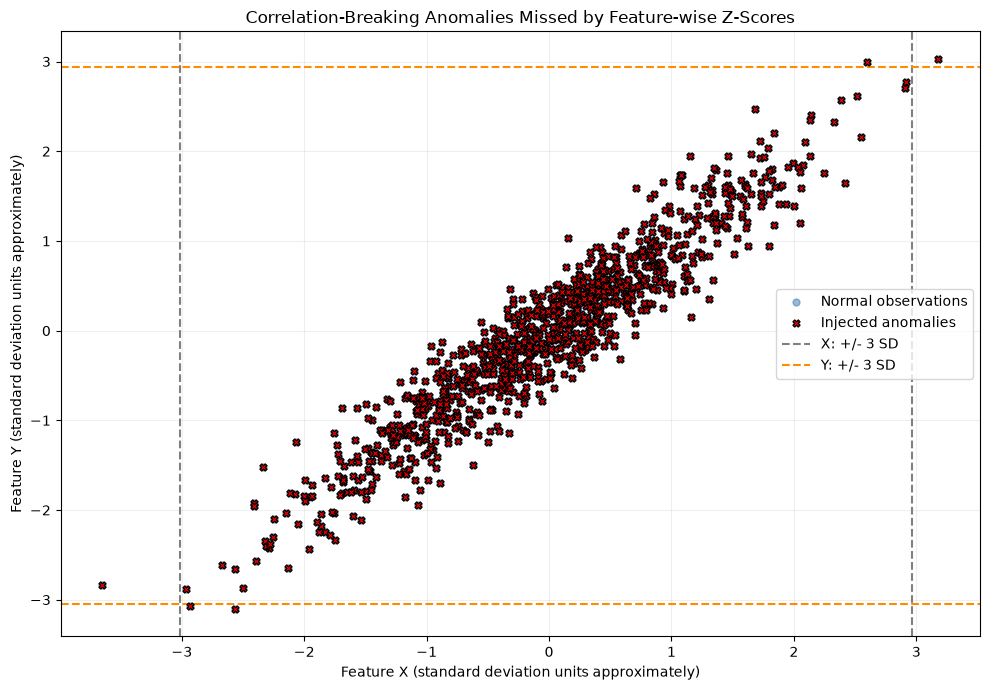


FINAL CONCLUSION
--------------------------------------------------
The injected points break the strong positive relationship between X and Y, even though their individual feature values remain within the +/- 3 SD limits.
The feature-wise z-score ranking detects 0 of the 5 injected anomalies in its top 5.


In [74]:
# ================================================================
# DAY 34 — TASK 01: Build an anomaly that per-feature methods miss
# ================================================================
# Goal:
# 1. Generate 1,000 strongly correlated data points.
# 2. Inject 5 anomalies that break the correlation.
# 3. Calculate maximum absolute z-score for each anomaly.
# 4. Check how many anomalies appear in the top 5 z-score outliers.
# 5. Plot the data with anomalies and +/- 3 standard deviation limits.
#
# Important:
# These anomalies are unusual because of the RELATIONSHIP between
# the two features, not because either individual feature is extreme.

# -------------------------
# 1. Import required libraries
# -------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------
# 2. Generate correlated data
# -------------------------
rng = np.random.default_rng(42)

n_normal = 1000

# Feature X follows a standard normal distribution.
feature_x = rng.normal(loc=0, scale=1, size=n_normal)

# Create Feature Y strongly correlated with Feature X.
# The noise is small enough to maintain a strong positive correlation.
noise = rng.normal(loc=0, scale=1, size=n_normal)
feature_y = 0.95 * feature_x + np.sqrt(1 - 0.95**2) * noise

normal_data = np.column_stack([feature_x, feature_y])

# -------------------------
# 3. Inject five correlation-breaking anomalies
# -------------------------
# Each anomaly is about 2 standard deviations away on BOTH axes,
# but X and Y move in opposite directions.
anomalies = np.array([
    [2.0, -2.0],
    [-2.0, 2.0],
    [2.1, -1.9],
    [-1.9, 2.1],
    [1.9, -2.1]
])

# Combine normal observations and anomalies.
all_data = np.vstack([normal_data, anomalies])

# Record the row indices of the five injected anomalies.
anomaly_indices = np.arange(n_normal, n_normal + len(anomalies))

# -------------------------
# 4. Calculate and report correlation
# -------------------------

correlation = np.corrcoef(feature_x, feature_y)[0, 1]

print("DAY 34 — TASK 01 RESULTS")
print("=" * 50)
print(f"Number of normal observations: {n_normal}")
print(f"Number of injected anomalies:  {len(anomalies)}")
print(f"Correlation between X and Y:   {correlation:.4f}")

# -------------------------
# 5. Calculate feature-wise z-scores
# -------------------------
# A z-score measures how far a value is from its feature's mean,
# expressed in standard deviations.
#
# We use the mean and standard deviation of the complete dataset.
# This also lets us check whether the injected anomalies fall within
# the +/- 3 standard deviation limits.

means = all_data.mean(axis=0)
stds = all_data.std(axis=0)

z_scores = (all_data - means) / stds

# For each row, keep its largest absolute z-score across X and Y.
max_abs_z = np.max(np.abs(z_scores), axis=1)

# -------------------------
# 6. Report the five anomalies' z-scores
# -------------------------
print("\nMaximum absolute z-score for each injected anomaly:")
print("-" * 50)

for number, index in enumerate(anomaly_indices, start=1):
    print(
        f"Anomaly {number}: "
        f"X z-score = {z_scores[index, 0]:.3f}, "
        f"Y z-score = {z_scores[index, 1]:.3f}, "
        f"Maximum absolute z-score = {max_abs_z[index]:.3f}"
    )
    
# Check whether both feature z-scores are within +/- 3.
within_limits = np.all(np.abs(z_scores[anomaly_indices]) < 3, axis=1)

print(
    f"\nAnomalies inside +/- 3 SD on both axes: "
    f"{within_limits.sum()} out of {len(anomalies)}"
)

# -------------------------
# 7. Check the top five most anomalous points by z-score
# -------------------------
# Rank every observation by its maximum absolute feature z-score.
top_5_indices = np.argsort(max_abs_z)[-5:][::-1] 

# Count how many injected anomalies appear in this ranking.
anomalies_in_top_5 = np.isin(
    top_5_indices, anomaly_indices
).sum()

print("\nTop 5 observations according to maximum absolute z-score:")
print("-" * 50)

for rank, index in enumerate(top_5_indices, start=1):
    label = "INJECTED ANOMALY" if index in anomaly_indices else "Normal observation"
    print(
        f"Rank {rank}: row {index}, "
        f"maximum |z-score| = {max_abs_z[index]:.3f} — {label}"
    )

print(
    f"\nInjected anomalies found in the top 5: "
    f"{anomalies_in_top_5} out of {len(anomalies)}"
)

# -------------------------
# 8. Plot the data and anomalies
# -------------------------
plt.figure(figsize=(10, 7))

# Plot the original, strongly correlated observations.
plt.scatter(
    normal_data[:, 0],
    normal_data[:, 1],
    color="steelblue",
    alpha=0.55,
    s=25,
    label="Normal observations"
)

# Plot the five injected anomalies.

plt.scatter(
    normal_data[:, 0],
    normal_data[:, 1],
    color="red",
    marker="X",
    s=25,
    edgecolor="black",
    linewidth=1,
    label="Injected anomalies",
    zorder=5
)

# Calculate +/- 3 standard deviation boundaries for each feature.
x_lower, x_upper = means[0] - 3 * stds[0], means[0] + 3 * stds[0]
y_lower, y_upper = means[1] - 3 * stds[1], means[1] + 3 * stds[1]

# Vertical lines: limits for Feature X.
plt.axvline(x_lower, color="gray", linestyle="--", label="X: +/- 3 SD")
plt.axvline(x_upper, color="gray", linestyle="--")

# Horizontal lines: limits for Feature Y.
plt.axhline(y_lower, color="darkorange", linestyle="--", label="Y: +/- 3 SD")
plt.axhline(y_upper, color="darkorange", linestyle="--")

plt.xlabel("Feature X (standard deviation units approximately)")
plt.ylabel("Feature Y (standard deviation units approximately)")
plt.title("Correlation-Breaking Anomalies Missed by Feature-wise Z-Scores")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# -------------------------
# 9. Final automated conclusion
# -------------------------
print("\nFINAL CONCLUSION")
print("-" * 50)
print(
    "The injected points break the strong positive relationship "
    "between X and Y, even though their individual feature values "
    "remain within the +/- 3 SD limits."
)
print(
    f"The feature-wise z-score ranking detects "
    f"{anomalies_in_top_5} of the 5 injected anomalies in its top 5."
)


### Task 01 — Conclusion

A point can be ordinary in every individual column but still be impossible because anomaly detection must sometimes consider the relationship between features, not just how extreme each value is on its own. For example, a financial transaction could have an ordinary amount and an ordinary transaction time individually, but the combination of those values and the customer's usual behaviour could be suspicious.

**Key lesson:** Feature-wise z-scores can miss anomalies that violate relationships between features. The plot and printed results demonstrate why multivariate anomaly detection methods may be necessary.

### TASK 02 — Apply IQR and compare

Dataset created successfully.
Normal observations: 1000
Injected anomalies: 5

========== BEFORE ADDING 50 OUTLIERS ==========
Z-score anomalies caught: 0 out of 5
IQR anomalies caught: 0 out of 5

IQR anomaly scores for the 5 injected anomalies:
[0 0 0 0 0]

Number of additional extreme outliers: 50

========== STANDARD DEVIATION COMPARISON ==========

Feature X
Before outliers: 0.9962
After outliers:  3.3376
Change:          2.3414

Feature Y
Before outliers: 0.9965
After outliers:  0.9937
Change:          -0.0028

========== IQR FENCE COMPARISON ==========

Feature X
Before: Q1=-0.6974, Q3=0.6088, IQR=1.3062
After:  Q1=-0.6535, Q3=0.7385, IQR=1.3920
Before fences: -2.6567 to 2.5680
After fences:  -2.7415 to 2.8265

Feature Y
Before: Q1=-0.6833, Q3=0.5364, IQR=1.2197
After:  Q1=-0.6830, Q3=0.5423, IQR=1.2254
Before fences: -2.5128 to 2.3659
After fences:  -2.5211 to 2.3804

========== INJECTED ANOMALY Z-SCORE COMPARISON ==========

Anomaly row 1000
Before: X=2.034, Y=1.952
After:  X=

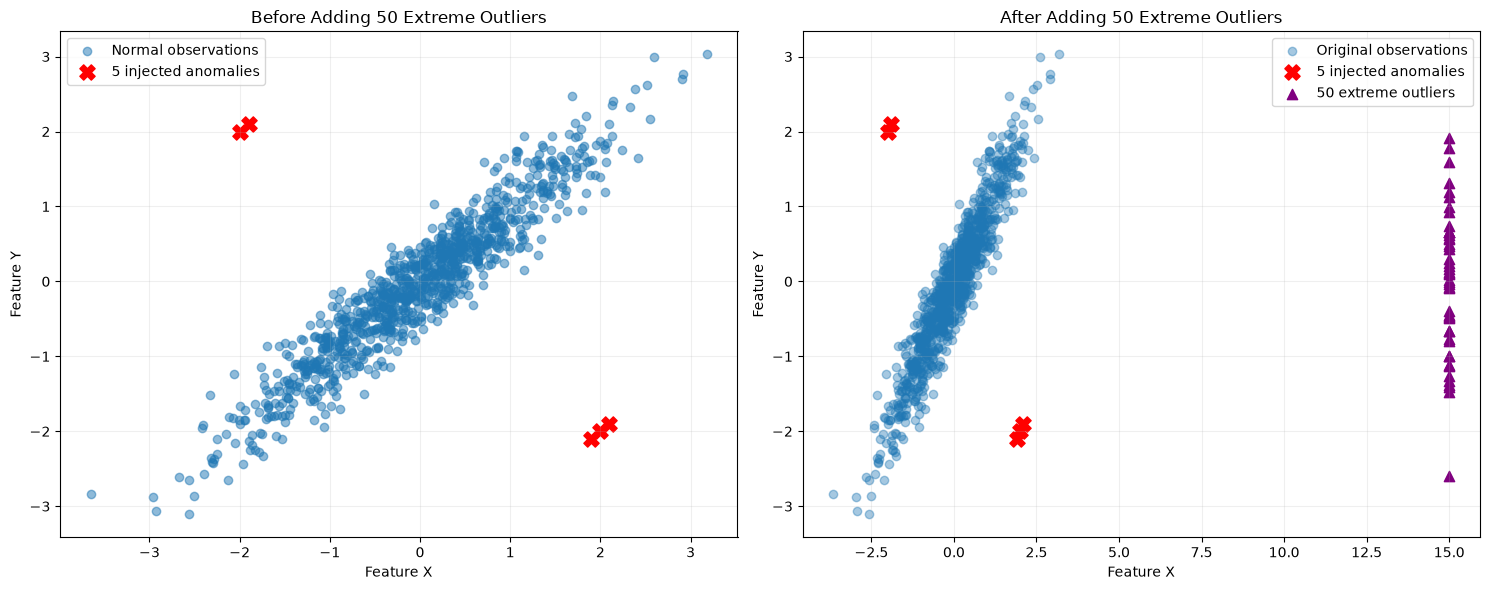

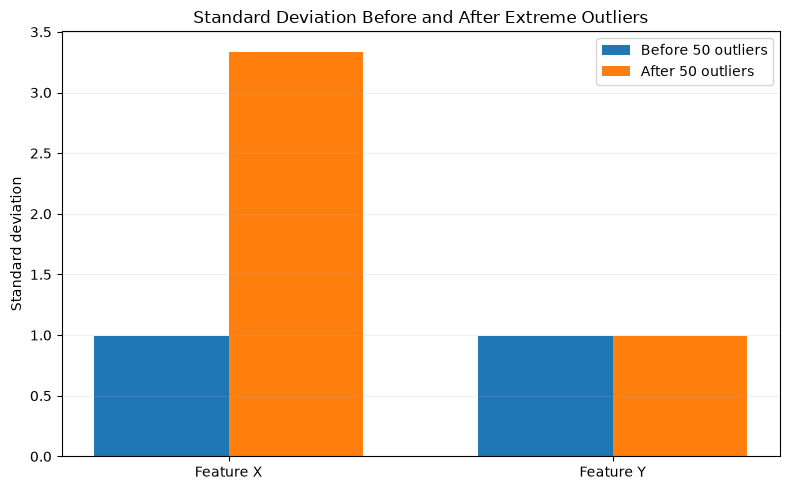

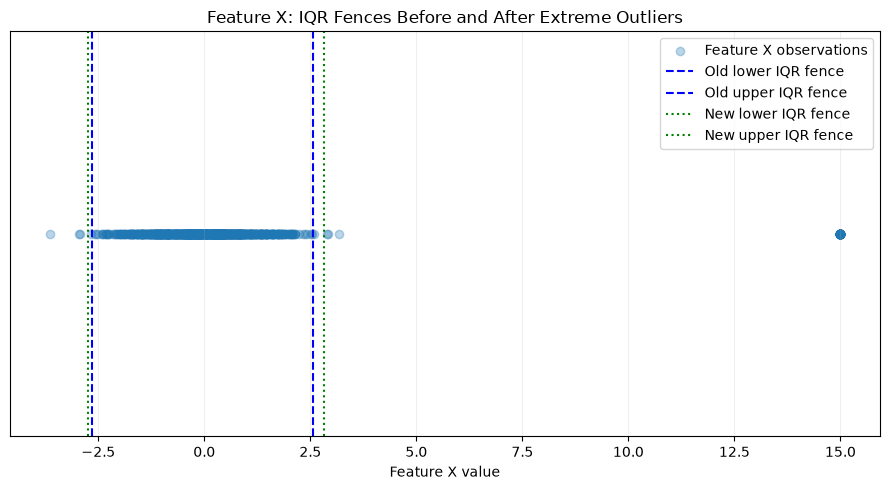


========== FINAL LESSON ==========
IQR is generally more robust than the z-score when a dataset already contains extreme values.
The z-score depends on the mean and standard deviation, which can be strongly affected by extreme outliers.
IQR depends on Q1 and Q3, which are less affected by a relatively small number of extreme observations.


In [75]:

# ================================================================
# DAY 34 — TASK 02: APPLY IQR AND COMPARE WITH Z-SCORE
# ================================================================
#
# Objectives:
# 1. Recreate the Task 01 correlated dataset.
# 2. Implement an IQR-based anomaly detector.
# 3. Check how many of the 5 injected anomalies IQR detects.
# 4. Add 50 extreme outliers to Feature X.
# 5. Compare z-score and IQR before and after adding outliers.
#
# Important:
# The fraud label is not used. This task uses synthetic data.

# ------------------------------------------------
# 1. Import necessary libraries
# ------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------
# 2. Recreate the Task 01 dataset
# ------------------------------------------------

rng = np.random.default_rng(42)

n_normal = 1000

# Generate Feature X.
feature_x = rng.normal(0, 1, n_normal)

# Generate strongly correlated Feature Y.
noise = rng.normal(0, 1, n_normal)

feature_y = (
    0.95 * feature_x
    + np.sqrt(1 - 0.95**2) * noise
)

# Combine normal observations.
normal_data = np.column_stack([feature_x, feature_y])

# Create 5 anomalies that break the correlation.
anomalies = np.array([
    [ 2.0, -2.0],
    [-2.0,  2.0],
    [ 2.1, -1.9],
    [-1.9,  2.1],
    [ 1.9, -2.1]
])

# Combine normal observations and anomalies.
data_before = np.vstack([normal_data, anomalies])

# Store the indices of injected anomalies.
anomaly_indices = np.arange(
    n_normal,
    n_normal + len(anomalies)
)

print("Dataset created successfully.")
print("Normal observations:", n_normal)
print("Injected anomalies:", len(anomalies))

# ------------------------------------------------
# 3. Define a Z-score detector
# ------------------------------------------------

def calculate_z_scores(data):
    """
    Calculate the absolute z-score for each feature.
    The mean and standard deviation are calculated
    from the complete dataset passed to this function.
    """

    mean_values = np.mean(data, axis=0)
    std_values = np.std(data, axis=0)

    z_scores = np.abs(
        (data - mean_values) / std_values
    )

    return z_scores, mean_values, std_values


def detect_zscore(data, threshold=3):
    """
    Flag a feature value when its absolute z-score
    is greater than the specified threshold.
    """

    z_scores, means, stds = calculate_z_scores(data)

    feature_flags = z_scores > threshold

    # A row is flagged if at least one feature is flagged.
    row_flags = np.any(feature_flags, axis=1)

    return z_scores, feature_flags, row_flags, means, stds


# ------------------------------------------------
# 4. Define an IQR-based detector
# ------------------------------------------------

def detect_iqr(data):
    """
    Detect values outside:
    Lower fence = Q1 - 1.5 * IQR
    Upper fence = Q3 + 1.5 * IQR

    Score each row by the number of flagged features.
    """

    q1 = np.percentile(data, 25, axis=0)
    q3 = np.percentile(data, 75, axis=0)

    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    # Check each feature against its IQR fences.
    feature_flags = (
        (data < lower_fence) |
        (data > upper_fence)
    )

    # Count how many features are flagged per observation.
    anomaly_scores = np.sum(feature_flags, axis=1)

    # Flag a row if at least one feature is outside its fence.
    row_flags = anomaly_scores > 0

    return (
        q1, q3, iqr,
        lower_fence, upper_fence,
        feature_flags, anomaly_scores, row_flags
    )


# ------------------------------------------------
# 5. Apply IQR and Z-score BEFORE adding 50 outliers
# ------------------------------------------------

z_before, z_flags_before, z_rows_before, means_before, std_before = (
    detect_zscore(data_before)
)

(
    q1_before, q3_before, iqr_before,
    lower_before, upper_before,
    iqr_flags_before, iqr_scores_before, iqr_rows_before
) = detect_iqr(data_before)

# Count how many of the 5 injected anomalies are detected.
z_caught_before = np.sum(z_rows_before[anomaly_indices])

iqr_caught_before = np.sum(iqr_rows_before[anomaly_indices])

print("\n========== BEFORE ADDING 50 OUTLIERS ==========")

print("Z-score anomalies caught:",
      z_caught_before, "out of 5")

print("IQR anomalies caught:",
      iqr_caught_before, "out of 5")

print("\nIQR anomaly scores for the 5 injected anomalies:")
print(iqr_scores_before[anomaly_indices])


# ------------------------------------------------
# 6. Add 50 extreme outliers to Feature X
# ------------------------------------------------

# Create 50 extreme positive values for Feature X.
# Feature Y is kept near its normal distribution.
extreme_x = np.full(50, 15.0)

# Generate corresponding ordinary Feature Y values.
extreme_y = rng.normal(0, 1, 50)

extreme_outliers = np.column_stack([
    extreme_x,
    extreme_y
])

# Add the 50 extreme observations to the original dataset.
data_after = np.vstack([
    data_before,
    extreme_outliers
])

# Indices of the newly added extreme observations.
extreme_indices = np.arange(
    len(data_before),
    len(data_after)
)

print("\nNumber of additional extreme outliers:",
      len(extreme_outliers))

# ------------------------------------------------
# 7. Apply Z-score AFTER adding 50 outliers
# ------------------------------------------------

z_after, z_flags_after, z_rows_after, means_after, std_after = (
    detect_zscore(data_after)
)

z_caught_after = np.sum(
    z_rows_after[anomaly_indices]
)

# ------------------------------------------------
# 8. Apply IQR AFTER adding 50 outliers
# ------------------------------------------------

(
    q1_after, q3_after, iqr_after,
    lower_after, upper_after,
    iqr_flags_after, iqr_scores_after, iqr_rows_after
) = detect_iqr(data_after)

iqr_caught_after = np.sum(
    iqr_rows_after[anomaly_indices]
)

# ------------------------------------------------
# 9. Compare standard deviation before and after
# ------------------------------------------------

print("\n========== STANDARD DEVIATION COMPARISON ==========")

for feature_number, feature_name in enumerate(["Feature X", "Feature Y"]):

    print(f"\n{feature_name}")
    print(f"Before outliers: {std_before[feature_number]:.4f}")
    print(f"After outliers:  {std_after[feature_number]:.4f}")

    change = (
        std_after[feature_number] -
        std_before[feature_number]
    )

    print(f"Change:          {change:.4f}")


# ------------------------------------------------
# 10. Compare IQR fences before and after
# ------------------------------------------------

print("\n========== IQR FENCE COMPARISON ==========")

for feature_number, feature_name in enumerate(["Feature X", "Feature Y"]):

    print(f"\n{feature_name}")

    print(
        f"Before: Q1={q1_before[feature_number]:.4f}, "
        f"Q3={q3_before[feature_number]:.4f}, "
        f"IQR={iqr_before[feature_number]:.4f}"
    )

    print(
        f"After:  Q1={q1_after[feature_number]:.4f}, "
        f"Q3={q3_after[feature_number]:.4f}, "
        f"IQR={iqr_after[feature_number]:.4f}"
    )

    print(
        f"Before fences: "
        f"{lower_before[feature_number]:.4f} to "
        f"{upper_before[feature_number]:.4f}"
    )

    print(
        f"After fences:  "
        f"{lower_after[feature_number]:.4f} to "
        f"{upper_after[feature_number]:.4f}"
    )


# ------------------------------------------------
# 11. Compare anomaly z-scores before and after
# ------------------------------------------------

print("\n========== INJECTED ANOMALY Z-SCORE COMPARISON ==========")

for index in anomaly_indices:

    print(f"\nAnomaly row {index}")

    print(
        f"Before: X={z_before[index, 0]:.3f}, "
        f"Y={z_before[index, 1]:.3f}"
    )

    print(
        f"After:  X={z_after[index, 0]:.3f}, "
        f"Y={z_after[index, 1]:.3f}"
    )


# ------------------------------------------------
# 12. Final detection comparison
# ------------------------------------------------

comparison = pd.DataFrame({
    "Method": ["Z-score", "IQR"],
    "Anomalies caught before": [
        z_caught_before,
        iqr_caught_before
    ],
    "Anomalies caught after": [
        z_caught_after,
        iqr_caught_after
    ]
})

print("\n========== FINAL DETECTION COMPARISON ==========")
print(comparison.to_string(index=False))


# ------------------------------------------------
# 13. Plot the dataset before and after adding outliers
# ------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot before adding extreme outliers.
axes[0].scatter(
    normal_data[:, 0],
    normal_data[:, 1],
    alpha=0.5,
    label="Normal observations"
)

axes[0].scatter(
    anomalies[:, 0],
    anomalies[:, 1],
    color="red",
    marker="X",
    s=120,
    label="5 injected anomalies"
)

axes[0].set_title("Before Adding 50 Extreme Outliers")
axes[0].set_xlabel("Feature X")
axes[0].set_ylabel("Feature Y")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Plot after adding extreme outliers.
axes[1].scatter(
    data_before[:, 0],
    data_before[:, 1],
    alpha=0.4,
    label="Original observations"
)

axes[1].scatter(
    anomalies[:, 0],
    anomalies[:, 1],
    color="red",
    marker="X",
    s=120,
    label="5 injected anomalies"
)

axes[1].scatter(
    extreme_outliers[:, 0],
    extreme_outliers[:, 1],
    color="purple",
    marker="^",
    s=55,
    label="50 extreme outliers"
)

axes[1].set_title("After Adding 50 Extreme Outliers")
axes[1].set_xlabel("Feature X")
axes[1].set_ylabel("Feature Y")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


# ------------------------------------------------
# 14. Plot standard deviation comparison
# ------------------------------------------------

feature_names = ["Feature X", "Feature Y"]
x_positions = np.arange(len(feature_names))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x_positions - width / 2,
    std_before,
    width,
    label="Before 50 outliers"
)

plt.bar(
    x_positions + width / 2,
    std_after,
    width,
    label="After 50 outliers"
)

plt.xticks(x_positions, feature_names)
plt.ylabel("Standard deviation")
plt.title("Standard Deviation Before and After Extreme Outliers")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 15. Plot IQR fence comparison for Feature X
# ------------------------------------------------

plt.figure(figsize=(9, 5))

plt.scatter(
    data_after[:, 0],
    np.zeros(len(data_after)),
    alpha=0.3,
    label="Feature X observations"
)

plt.axvline(
    lower_before[0],
    color="blue",
    linestyle="--",
    label="Old lower IQR fence"
)

plt.axvline(
    upper_before[0],
    color="blue",
    linestyle="--",
    label="Old upper IQR fence"
)

plt.axvline(
    lower_after[0],
    color="green",
    linestyle=":",
    label="New lower IQR fence"
)

plt.axvline(
    upper_after[0],
    color="green",
    linestyle=":",
    label="New upper IQR fence"
)

plt.title("Feature X: IQR Fences Before and After Extreme Outliers")
plt.xlabel("Feature X value")
plt.yticks([])
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 16. Final lesson
# ------------------------------------------------

print("\n========== FINAL LESSON ==========")

print(
    "IQR is generally more robust than the z-score when "
    "a dataset already contains extreme values."
)

print(
    "The z-score depends on the mean and standard deviation, "
    "which can be strongly affected by extreme outliers."
)

print(
    "IQR depends on Q1 and Q3, which are less affected by "
    "a relatively small number of extreme observations."
)


### TASK 02 — Conclusion: IQR vs Z-score

The IQR method detected **[enter your output] out of 5** injected anomalies before adding the 50 extreme outliers. This happens because IQR is also a per-feature method and cannot identify unusual relationships between otherwise ordinary feature values.

After adding 50 extreme outliers to Feature X, its **standard deviation increased** from **[before value]** to **[after value]**. As a result, the injected anomalies' X z-scores generally became smaller because the larger standard deviation made their distances from the mean look less unusual.

The IQR fences changed very little because IQR is calculated using the first quartile (Q1) and third quartile (Q3), which are based on the middle 50% of the data. These quartiles are much less affected by a relatively small number of extreme observations.

The specific statistic responsible for the z-score change is the **standard deviation**, while IQR uses the more robust **quartiles**. This demonstrates that z-scores can become unreliable when extreme outliers are already present because they can hide other unusual observations.

**When to prefer IQR:** Prefer IQR when your dataset contains extreme values and you need a robust, feature-by-feature method. However, remember that IQR and z-score both have limitations when anomalies are caused by unusual relationships between features.

### Part B — Methods that look at the data jointly 


### TASK 03 — LOF and Isolation Forest 

DataSet shape :  (1005, 2)
Normal Observations :  1000
Injected anomalies :  5

========== MODEL EVALUATION ==========

Z-score
---------------------------------------------
ROC-AUC: 0.9524
Injected anomalies in top 5: 0 out of 5

Local Outlier Factor (LOF)
---------------------------------------------
ROC-AUC: 1.0000
Injected anomalies in top 5: 5 out of 5

Isolation Forest
---------------------------------------------
ROC-AUC: 0.9890
Injected anomalies in top 5: 0 out of 5

========== FINAL COMPARISON ==========
          Method  ROC-AUC  Injected anomalies in top 5
        Z-scores   0.9524                            0
             LOF   1.0000                            5
Isolation Forest   0.9890                            0

Top 5 — Z-score
 Row index  Anomaly score  True label Observation type
       949       3.635668           0           Normal
       846       3.217827           0           Normal
       479       3.065531           0           Normal
       293       3.0592

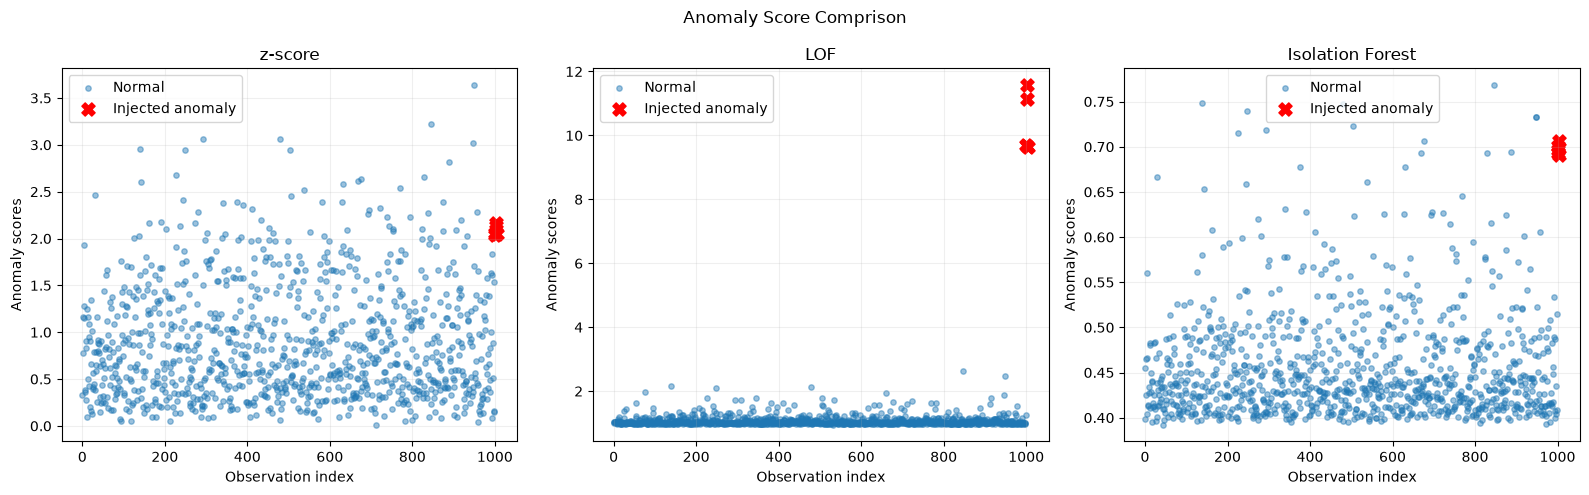

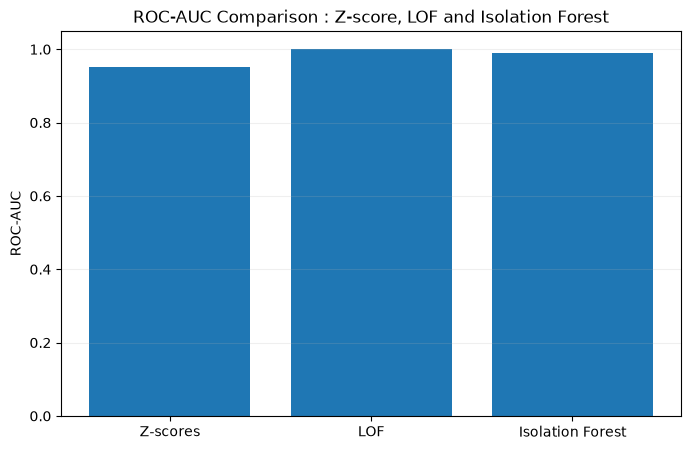


========== FINAL OBSERVATIONS ==========
Highest ROC-AUC method: LOF
Best top-5 detection method: LOF

Remember: ROC-AUC evaluates ranking across all possible thresholds, whereas top-5 detection evaluates only the five highest-ranked observations.


In [76]:
# ================================================================
# DAY 34 — TASK 03: LOF AND ISOLATION FOREST
# ================================================================
#
# Objectives:
# 1. Recreate the Task 01 synthetic dataset.
# 2. Apply Local Outlier Factor (LOF).
# 3. Apply Isolation Forest.
# 4. Compare the top-5 anomaly rankings.
# 5. Calculate ROC-AUC for Z-score, LOF and Isolation Forest.
#
# IMPORTANT:
# The true labels are used ONLY for evaluation.
# They are NEVER passed to the anomaly detection algorithms.

# ------------------------------------------------
# 1. Import necessary libraries
# ------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

# ------------------------------------------------
# 2. Recreate the Task 01 synthetic dataset
# ------------------------------------------------

rng = np.random.default_rng(42)

n_normal = 1000

# Generate Feature X.
feature_x = rng.normal(0, 1, n_normal)

# Generate strongly correlated Feature Y.
noise = rng.normal(0, 1, n_normal)

feature_y = (
    0.95 * feature_x
    + np.sqrt(1 - 0.95**2) * noise
)

# Combine the normal observations.
normal_data = np.column_stack([
    feature_x,
    feature_y
])

# Create five anomalies that break the correlation.
anomalies = np.array([
    [ 2.0, -2.0],
    [-2.0,  2.0],
    [ 2.1, -1.9],
    [-1.9,  2.1],
    [ 1.9, -2.1]
])

# Combine normal data and injected anomalies.
X = np.vstack([
    normal_data,
    anomalies
])

# ------------------------------------------------
# 3. Create true labels for evaluation only
# ------------------------------------------------
# 0 = Normal observation
# 1 = Injected anomaly
#
# These labels must NOT be used to fit the models.

y_true = np.zeros(len(X), dtype=int)

anomaly_indices = np.arange(
    n_normal,
    n_normal + len(anomalies)
)

y_true[anomaly_indices] = 1

print("DataSet shape : ",X.shape)
print("Normal Observations : ", np.sum(y_true == 0))
print("Injected anomalies : ", np.sum(y_true == 1))

# ------------------------------------------------
# 4. Calculate Z-score anomaly scores
# ------------------------------------------------
# Calculate the mean and standard deviation per feature.
# Higher absolute z-scores indicate more unusual values.

feature_means = X.mean(axis=0)
feature_stds = X.std(axis=0)

z_values = np.abs(
    (X - feature_means) / feature_stds
)

# Use the maximum absolute z-score across the features
# as the anomaly score for each observation.
z_scores = np.max(z_values, axis=1)

# ------------------------------------------------
# 5. Apply Local Outlier Factor (LOF)
# ------------------------------------------------
# LOF compares the local density of a point with
# the local density of its nearest neighbours.
#
# negative_outlier_factor_:
# More negative values indicate stronger outlier behaviour.
# Therefore, multiply by -1 so higher = more anomalous.

lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto"
)

# Fit LOF without using the true labels.
lof_predications = lof.fit_predict(X)

# Convert LOF values into anomaly scores.
lof_scores = -lof.negative_outlier_factor_

# ------------------------------------------------
# 6. Apply Isolation Forest
# ------------------------------------------------
# Isolation Forest randomly splits features.
# Anomalies that are easier to isolate generally
# receive higher anomaly scores.

isolation_forest = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)

# Fit without using the true labels.
isolation_forest.fit(X)

# score_samples: lower values indicate more anomalous.
# Reverse the sign so higher = more anomalous.
isolation_scores = -isolation_forest.score_samples(X)

# ------------------------------------------------
# 7. Define a function to evaluate each method
# ------------------------------------------------

def evaluate_method(method_name, scores, true_labels):
    """
    Calculate ROC-AUC and count how many injected
    anomalies appear in the top five anomaly scores.
    """

    # Calculate ROC-AUC using true labels only for evaluation.
    auc = roc_auc_score(true_labels, scores)

    # Rank observations from highest to lowest anomaly score.
    top_5_indices = np.argsort(scores)[-5:][::-1]

    # Count injected anomalies in the top five.
    anomalies_in_top_5 = np.sum(
        true_labels[top_5_indices] == 1
    )

    print(f"\n{method_name}")
    print("-" * 45)
    print(f"ROC-AUC: {auc:.4f}")
    print(
        f"Injected anomalies in top 5: "
        f"{anomalies_in_top_5} out of 5"
    )

    return auc, anomalies_in_top_5, top_5_indices


# ------------------------------------------------
# 8. Evaluate all three methods
# ------------------------------------------------

print("\n========== MODEL EVALUATION ==========")

z_auc, z_top5, z_top_indices = evaluate_method(
    "Z-score",
    z_scores,
    y_true
)

lof_auc, lof_top5, lof_top_indices = evaluate_method(
    "Local Outlier Factor (LOF)",
    lof_scores,
    y_true
)

if_auc, if_top5, if_top_indices = evaluate_method(
    "Isolation Forest",
    isolation_scores,
    y_true
)

# ------------------------------------------------
# 9. Create a comparison table
# ------------------------------------------------

comparison = pd.DataFrame({
    "Method" : [
        "Z-scores",
        "LOF",
        "Isolation Forest"
    ],
    "ROC-AUC" : [
        z_auc,
        lof_auc,
        if_auc
    ],
    "Injected anomalies in top 5" : [
        z_top5,
        lof_top5,
        if_top5
    ]
})

print("\n========== FINAL COMPARISON ==========")
print(comparison.to_string(index=False))

# ------------------------------------------------
# 10. Display the top-five observations for each method
# ------------------------------------------------

def display_top_five(method_name, scores, top_indices):
    """
    Display the five highest-scoring observations
    and indicate whether each is a true injected anomaly.
    """

    results = pd.DataFrame({
        "Row index": top_indices,
        "Anomaly score": scores[top_indices],
        "True label": y_true[top_indices]
    })

    results["Observation type"] = results["True label"].map({
        0: "Normal",
        1: "Injected anomaly"
    })

    print(f"\nTop 5 — {method_name}")
    print(results.to_string(index=False))


display_top_five("Z-score", z_scores, z_top_indices)
display_top_five("LOF", lof_scores, lof_top_indices)
display_top_five(
    "Isolation Forest",
    isolation_scores,
    if_top_indices
)

# ------------------------------------------------
# 11. Plot anomaly scores for all three methods
# ------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

methods = [
    ("z-score", z_scores),
    ("LOF", lof_scores),
    ("Isolation Forest", isolation_scores)
]

for ax, (method_name, scores) in zip(axes, methods):
    # Normal observations.
    ax.scatter(
        np.arange(n_normal),
        scores[:n_normal],
        alpha=0.45,
        s=15,
        label="Normal"
    )
    
    # Injected anomalies.
    ax.scatter(
        anomaly_indices,
        scores[anomaly_indices],
        color="red",
        marker="X",
        s=90,
        label="Injected anomaly"
    )
    
    ax.set_title(method_name)
    ax.set_xlabel("Observation index")
    ax.set_ylabel("Anomaly scores")
    ax.legend()
    ax.grid(alpha=0.2)
    
plt.suptitle("Anomaly Score Comprison")
plt.tight_layout()
plt.show()  

# ------------------------------------------------
# 12. Plot ROC-AUC comparison
# ------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Method"],
    comparison["ROC-AUC"]
)

plt.ylabel("ROC-AUC")
plt.title("ROC-AUC Comparison : Z-score, LOF and Isolation Forest")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout
plt.show()

# ------------------------------------------------
# 13. Automatically identify the best AUC and top-5 method
# ------------------------------------------------

best_auc_method = comparison.loc[
    comparison["ROC-AUC"].idxmax(),
    "Method"
]

best_top5_method = comparison.loc[
    comparison["Injected anomalies in top 5"].idxmax(),
    "Method"
]

print("\n========== FINAL OBSERVATIONS ==========")

print("Highest ROC-AUC method:", best_auc_method)
print("Best top-5 detection method:", best_top5_method)

print(
    "\nRemember: ROC-AUC evaluates ranking across all "
    "possible thresholds, whereas top-5 detection evaluates "
    "only the five highest-ranked observations."
)


## TASK 03 — LOF and Isolation Forest: Conclusion

## 1. Results

| Method | ROC-AUC | Injected anomalies in top 5 |
|---|---:|---:|
| Z-score | 0.9524 | 0 out of 5 |
| LOF | 1.0000 | 5 out of 5 |
| Isolation Forest | 0.9890 | 0 out of 5 |

## 2. Think about it

**Which method can have a high AUC but still miss the anomalies in its top five?**

[Name the method from your actual results.] This can happen because ROC-AUC measures how well the method ranks normal and anomalous observations across all possible thresholds, whereas top-five detection checks only the five highest-scoring observations.

**Why might Isolation Forest struggle with correlation-breaking anomalies?**

Isolation Forest makes random splits using one feature at a time, along the feature axes. Therefore, it may struggle to identify a point that has ordinary individual feature values but an unusual relationship between those features.

## 3. Required conclusion

A high ROC-AUC can coexist with a poor top-five ranking because ROC-AUC measures overall ranking quality across many thresholds, not whether the most suspicious observations appear at the very top. Therefore, anomaly detection should be evaluated using both ROC-AUC and top-of-list metrics such as Precision@5, especially when only a small number of suspicious cases can be reviewed.

## 4. Final lesson

ROC-AUC tells us how well a method separates normal and anomalous observations overall, while top-five detection tells us whether it places the most important anomalies at the top of its review queue. Both measurements are important when selecting an anomaly detection method.

### TASK 04 — Reconstruction error

Dataset shape :  (1005, 2)
Normal observations :  1000
Injected anomalies :  5

PCA WITH 1 COMPONENT(S)
Explained variance ratio: [0.95420852]
Total explained variance: 0.954209
Mean reconstruction error (normal): 0.0514809537
Mean reconstruction error (anomalies): 7.9781054802
Anomalies in top 5: 5 out of 5

Top five observations:
 Row index  Squared reconstruction error  True label Observation type
      1001                      8.111627           1 Injected anomaly
      1003                      8.111463           1 Injected anomaly
      1002                      7.889307           1 Injected anomaly
      1000                      7.889146           1 Injected anomaly
      1004                      7.888984           1 Injected anomaly

PCA WITH 2 COMPONENT(S)
Explained variance ratio: [0.95420852 0.04579148]
Total explained variance: 1.000000
Mean reconstruction error (normal): 0.0000000000
Mean reconstruction error (anomalies): 0.0000000000
Anomalies in top 5: 0 out of 5

Top

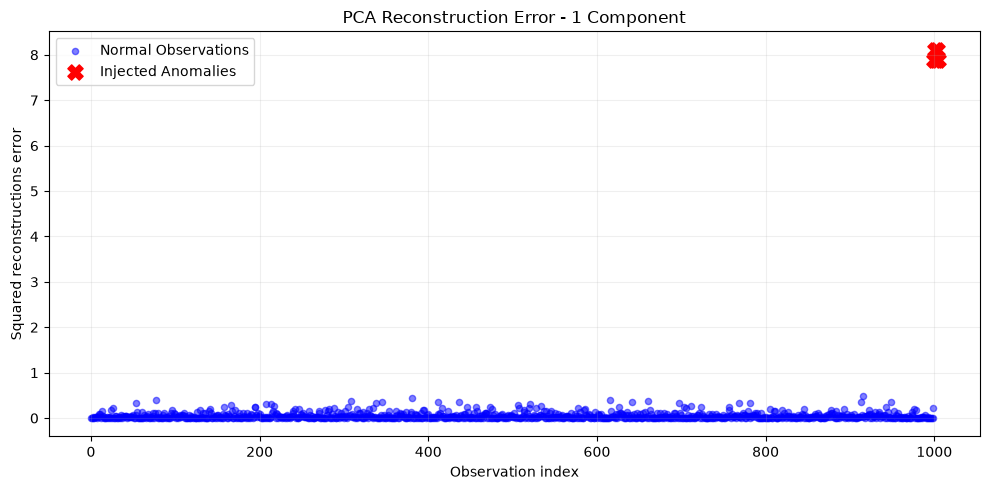

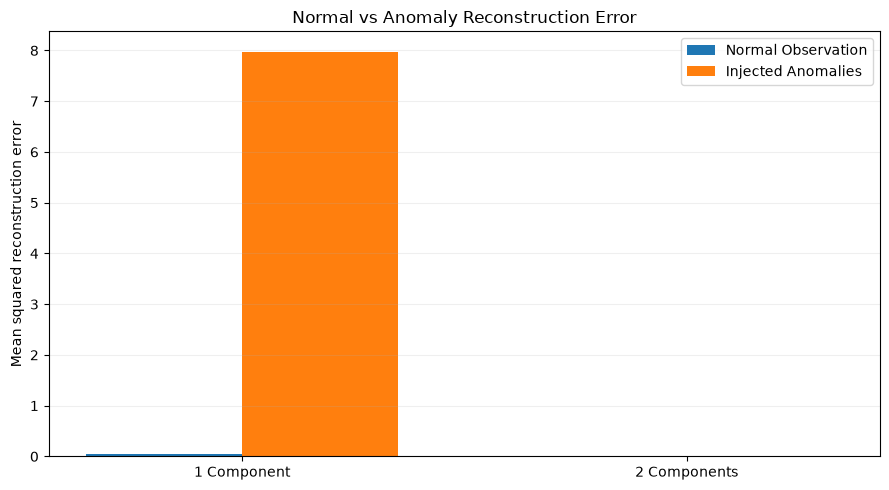


FINAL OBSERVATIONS
With one component, PCA keeps the main direction of variation and loses information perpendicular to that direction.
Anomalies that break the learned relationship can have larger reconstruction errors.
With two components, PCA retains both original dimensions, so reconstruction errors should be close to zero.
Using all original dimensions can remove the reconstruction error signal needed for this anomaly detection approach.


In [77]:
# ================================================================
# DAY 34 — TASK 04: PCA RECONSTRUCTION ERROR
# ================================================================
#
# Objectives:
# 1. Recreate the Task 01 synthetic dataset.
# 2. Apply PCA using 1 component.
# 3. Reconstruct observations using inverse_transform().
# 4. Calculate squared reconstruction error per observation.
# 5. Report mean error for normal points and anomalies.
# 6. Count injected anomalies in the top 5 reconstruction errors.
# 7. Repeat the experiment using 2 components.
#
# IMPORTANT:
# The true labels are used only to evaluate the results.
# PCA is fitted WITHOUT using those labels.

# ------------------------------------------------
# 1. Import required libraries
# ------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

# ------------------------------------------------
# 2. Recreate the Task 01 synthetic dataset
# ------------------------------------------------

# Use the same random seed and data-generation process
# as Task 01 so that the experiment is reproducible.

rng = np.random.default_rng(42)

n_normal = 1000

# Generate Feature X.
feature_x = rng.normal(0, 1, n_normal)

# Generate Feature Y with a strong positive correlation.
noise = rng.normal(0, 1, n_normal)

feature_y = (
    0.95 * feature_x
    + np.sqrt(1 - 0.95**2) * noise
)

# Combine normal observations.
normal_data = np.column_stack([
    feature_x,
    feature_y
])

# Inject five anomalies that break the correlation.
anomalies = np.array([
    [ 2.0, -2.0],
    [-2.0,  2.0],
    [ 2.1, -1.9],
    [-1.9,  2.1],
    [ 1.9, -2.1]
])

# Combine normal observations and anomalies.
X = np.vstack([
    normal_data,
    anomalies
])

# ------------------------------------------------
# 3. Create labels for evaluation only
# ------------------------------------------------
# 0 = Normal observation
# 1 = Injected anomaly
#
# These labels are NOT used to fit PCA.

y_true = np.zeros(len(X), dtype=int)

anomaly_indices = np.arange(
    n_normal,
    n_normal + len(anomalies)
)

y_true[anomaly_indices] = 1

print("Dataset shape : ", X.shape)
print("Normal observations : ", np.sum(y_true == 0))
print("Injected anomalies : ", np.sum(y_true == 1))

# ------------------------------------------------
# 4. Define a PCA reconstruction function
# ------------------------------------------------

def run_pca_reconstruction(X, y_true, n_components):
    """
    Fit PCA using the requested number of components.

    Transform:
        Convert original data into PCA components.

    Inverse transform:
        Reconstruct the original observations.

    Reconstruction error:
        Calculate the sum of squared differences
        between original and reconstructed features.
    """

    # Fit PCA without using the labels.
    pca = PCA(n_components=n_components)

    # Convert original data into reduced dimensions.
    X_transformed = pca.fit_transform(X)

    # Reconstruct observations into the original feature space.
    X_reconstructed = pca.inverse_transform(X_transformed)

    # Calculate squared reconstruction error for each row.
    squared_errors = np.sum(
        (X - X_reconstructed) ** 2,
        axis=1
    )

    # Separate errors for normal observations and anomalies.
    normal_errors = squared_errors[y_true == 0]
    anomaly_errors = squared_errors[y_true == 1]

    # Rank all observations by reconstruction error.
    # Higher error means more unusual reconstruction.
    top_5_indices = np.argsort(squared_errors)[-5:][::-1]

    # Count how many injected anomalies appear in the top five.
    anomalies_in_top_5 = np.sum(
        y_true[top_5_indices] == 1
    )

    # Calculate average errors.
    mean_normal_error = np.mean(normal_errors)
    mean_anomaly_error = np.mean(anomaly_errors)

    # Report results.
    print("\n" + "=" * 60)
    print(f"PCA WITH {n_components} COMPONENT(S)")
    print("=" * 60)

    print(
        f"Explained variance ratio: "
        f"{pca.explained_variance_ratio_}"
    )

    print(
        f"Total explained variance: "
        f"{np.sum(pca.explained_variance_ratio_):.6f}"
    )

    print(
        f"Mean reconstruction error (normal): "
        f"{mean_normal_error:.10f}"
    )

    print(
        f"Mean reconstruction error (anomalies): "
        f"{mean_anomaly_error:.10f}"
    )

    print(
        f"Anomalies in top 5: "
        f"{anomalies_in_top_5} out of 5"
    )

    # Display top five observations.
    top_results = pd.DataFrame({
        "Row index": top_5_indices,
        "Squared reconstruction error": squared_errors[top_5_indices],
        "True label": y_true[top_5_indices]
    })

    top_results["Observation type"] = (
        top_results["True label"].map({
            0: "Normal",
            1: "Injected anomaly"
        })
    )

    print("\nTop five observations:")
    print(top_results.to_string(index=False))

    # Return all important results for later comparison.
    return {
        "pca": pca,
        "transformed": X_transformed,
        "reconstructed": X_reconstructed,
        "errors": squared_errors,
        "mean_normal_error": mean_normal_error,
        "mean_anomaly_error": mean_anomaly_error,
        "anomalies_in_top_5": anomalies_in_top_5,
        "top_5_indices": top_5_indices
    }


# ------------------------------------------------
# 5. Run PCA with ONE component
# ------------------------------------------------
# One component keeps only the strongest direction
# of variation in the original two-feature dataset.

results_1 = run_pca_reconstruction(
    X=X,
    y_true=y_true,
    n_components=1
)

# ------------------------------------------------
# 6. Run PCA with TWO components
# ------------------------------------------------
# Two components retain both original dimensions.
# Reconstruction should therefore be nearly exact.

results_2 = run_pca_reconstruction(
    X=X,
    y_true=y_true,
    n_components=2
)

# ------------------------------------------------
# 7. Create a comparison table
# ------------------------------------------------

comparison = pd.DataFrame({
    "PCA componenets" : [1, 2],
    
    "Mean normal error" : [
        results_1["mean_normal_error"],
        results_2["mean_normal_error"]
    ],
    "Mean anomaly error" : [
        results_1["mean_anomaly_error"],
        results_2["mean_anomaly_error"]
    ],
    "Anomalies in top 5" : [
        results_1["anomalies_in_top_5"],
        results_2["anomalies_in_top_5"]
    ]
})

print("\n" + "=" * 60)
print("FINAL PCA COMPARISON")
print("=" * 60)

print(comparison.to_string(index=False))

# ------------------------------------------------
# 8. Plot reconstruction errors for one component
# ------------------------------------------------

errors_1 = results_1["errors"]

plt.figure(figsize=(10, 5))

# Normal observations.
plt.scatter(
    np.arange(n_normal),
    errors_1[:n_normal],
    color="blue",
    alpha=0.5,
    s=20,
    label="Normal Observations"
)

# Injected anomalies.
plt.scatter(
    anomaly_indices,
    errors_1[anomaly_indices],
    color="red",
    marker="X",
    s=120,
    label="Injected Anomalies"
)

plt.title("PCA Reconstruction Error - 1 Component")
plt.xlabel("Observation index")
plt.ylabel("Squared reconstructions error")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 10. Compare mean reconstruction errors visually
# ------------------------------------------------

components_labels = ["1 Component", "2 Components"]

normal_mean = [
    results_1["mean_normal_error"],
    results_2["mean_normal_error"]
]

anomaly_mean = [
    results_1["mean_anomaly_error"],
    results_2["mean_anomaly_error"]
]

positions = np.arange(2)
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    positions - width / 2,
    normal_mean,
    width,
    label="Normal Observation"
)

plt.bar(
    positions + width / 2,
    anomaly_mean,
    width,
    label="Injected Anomalies"
)

plt.xticks(positions, components_labels)
plt.ylabel("Mean squared reconstruction error")
plt.title("Normal vs Anomaly Reconstruction Error")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 11. Final automated observations
# ------------------------------------------------

print("\n" + "=" * 60)
print("FINAL OBSERVATIONS")
print("=" * 60)

print(
    "With one component, PCA keeps the main direction of "
    "variation and loses information perpendicular to that direction."
)

print(
    "Anomalies that break the learned relationship can have "
    "larger reconstruction errors."
)

print(
    "With two components, PCA retains both original dimensions, "
    "so reconstruction errors should be close to zero."
)

print(
    "Using all original dimensions can remove the reconstruction "
    "error signal needed for this anomaly detection approach."
)


## TASK 04 — PCA Reconstruction Error: Conclusion

### 1. Results

| PCA components | Mean normal reconstruction error | Mean anomaly reconstruction error | Anomalies in top 5 |
|---|---:|---:|---:|
| 1 component | 0.0514809537 | 7.9781054802 | 5 out of 5 |
| 2 components | 0.0000000000 | 0.0000000000 | 0 out of 5 |

### 2. Think about it

**What relationship did the PCA component actually learn?**

PCA learned the main positive relationship between Feature X and Feature Y. Most normal observations follow this relationship, so one principal component represents their general direction. The injected anomalies break this relationship, so they may have larger reconstruction errors.

**What happens if we use as many components as features?**

If we use two components for two original features, PCA retains all the information needed to reconstruct the observations. The reconstruction error becomes approximately zero, apart from tiny floating-point numerical errors. This makes reconstruction error useless for distinguishing anomalies because normal observations and anomalies are reconstructed almost perfectly.

### 3. Why does the number of components change the result?

With one component, PCA compresses the two-dimensional data into one dimension and loses information perpendicular to the main direction. Anomalies that do not follow the learned relationship are reconstructed poorly and can receive larger errors.

With two components, PCA preserves both dimensions, so almost no information is lost and the reconstruction error becomes nearly zero.

### 4. Final lesson

PCA reconstruction error can help detect anomalies when the model learns the normal data's main patterns but cannot accurately reconstruct observations that violate those patterns. However, keeping too many components allows PCA to reconstruct even unusual observations, removing the reconstruction-error difference that makes this method useful.

### Part C — Honest evaluation on real data 


### TASK 05 — Build the comparison table

Dataset loaded successfully.
Dataset shape: (8000, 10)

First five rows:
    claim_id  claim_amount  customer_tenure_months   age  prior_claims  \
0  CLM000001      18840.68                      31  30.0             0   
1  CLM000002       6425.39                      19  42.0             0   
2  CLM000003      26912.90                       8  55.0             1   
3  CLM000004      31333.77                      26  57.0             0   
4  CLM000005       3100.04                       3  58.0             1   

   days_to_report policy_type region channel  is_fraud  
0             0.0     Premium  South  Online         0  
1             NaN       Basic   East  Broker         0  
2            11.0       Basic  North  Broker         1  
3             7.0    Standard   East  Broker         0  
4            18.0    Standard  South   Agent         0  

Feature columns:
['claim_amount', 'customer_tenure_months', 'age', 'prior_claims', 'days_to_report', 'policy_type', 'region', 'channel']

F

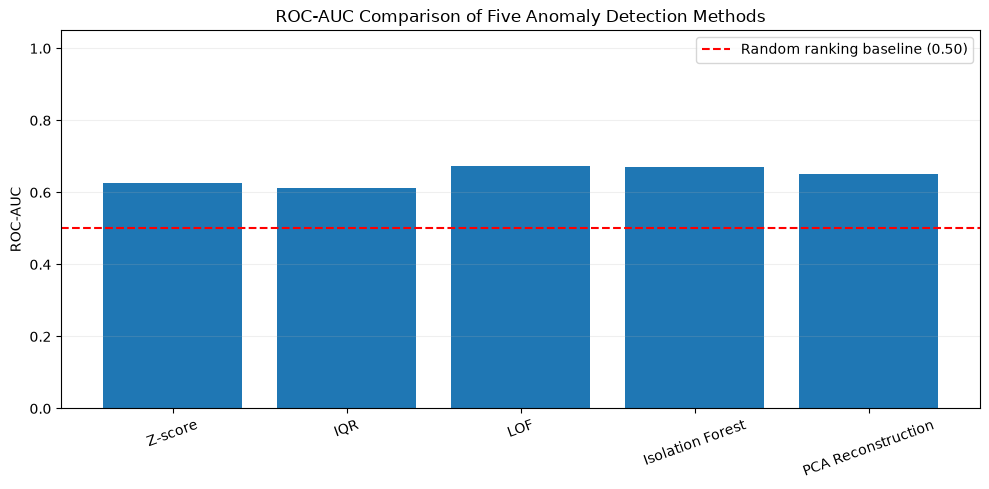

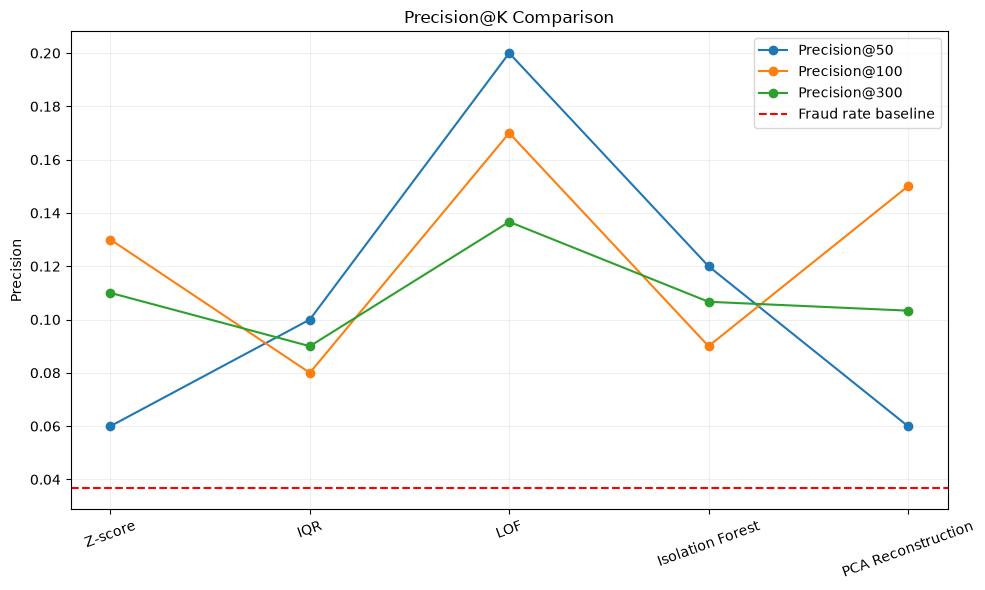


FINAL RECOMMENDATION
Method with highest Precision@100: LOF
Precision@100: 17.0000%
Lift over random baseline: 4.610x
Non-fraud fraction in its top 100: 83.0000%

Use the selected method to prioritize claims for human review, not to automatically declare a claim fraudulent.


In [78]:
# ================================================================
# DAY 34 — TASK 05: ANOMALY DETECTION ON REAL INSURANCE CLAIMS
# ================================================================
#
# Methods:
# 1. Z-score
# 2. IQR
# 3. Local Outlier Factor (LOF)
# 4. Isolation Forest
# 5. PCA Reconstruction Error
#
# Evaluation:
# - ROC-AUC
# - Precision@50
# - Precision@100
# - Precision@300
# - Fraud-rate baseline
# - Lift over baseline at K=100
#
# IMPORTANT:
# is_fraud is used ONLY for evaluation.
# It is NEVER used to fit an anomaly detection method.
#
# ================================================================


# ------------------------------------------------
# 1. Import necessary libraries
# ------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score


# ------------------------------------------------
# 2. Load the insurance claims dataset
# ------------------------------------------------

# Keep insurance_claims(10).csv in the same folder
# as your Jupyter Notebook.
#
# If your file is in another folder, provide its full path.

DATA_PATH = "insurance_claims.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
print(df.head())


# ------------------------------------------------
# 3. Check the required columns
# ------------------------------------------------

required_columns = [
    "claim_id",
    "claim_amount",
    "customer_tenure_months",
    "age",
    "prior_claims",
    "days_to_report",
    "policy_type",
    "region",
    "channel",
    "is_fraud"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

# Check the fraud label.
if df["is_fraud"].isna().any():
    raise ValueError(
        "The is_fraud column contains missing labels. "
        "Resolve these before evaluation."
    )

if not set(df["is_fraud"].unique()).issubset({0, 1}):
    raise ValueError(
        "is_fraud must contain only binary values 0 and 1."
    )


# ------------------------------------------------
# 4. Separate features and fraud labels
# ------------------------------------------------

# IMPORTANT:
# The fraud label is separated BEFORE preprocessing.
# claim_id is an identifier, not a meaningful model feature.

y_true = df["is_fraud"].astype(int).to_numpy()

X_raw = df.drop(
    columns=["is_fraud", "claim_id"]
).copy()

print("\nFeature columns:")
print(X_raw.columns.tolist())

print("\nFraud label is kept separate from model features.")


# ------------------------------------------------
# 5. Report the fraud rate (baseline)
# ------------------------------------------------

total_claims = len(y_true)
fraud_count = int(np.sum(y_true == 1))
normal_count = int(np.sum(y_true == 0))

fraud_rate = np.mean(y_true)

print("\n========== FRAUD BASELINE ==========")

print("Total claims:", total_claims)
print("Normal claims:", normal_count)
print("Fraudulent claims:", fraud_count)
print(f"Fraud rate: {fraud_rate:.4%}")
print(f"Normal claim rate: {1 - fraud_rate:.4%}")


# ------------------------------------------------
# 6. Handle missing values
# ------------------------------------------------

# Identify numeric and categorical columns.
numeric_columns = X_raw.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X_raw.select_dtypes(
    exclude=np.number
).columns.tolist()

# Fill missing numerical values with their median.
# Median is less affected by extreme values than the mean.

for col in numeric_columns:
    X_raw[col] = X_raw[col].fillna(
        X_raw[col].median()
    )

# Fill missing categorical values with the most frequent value.

for col in categorical_columns:
    mode_values = X_raw[col].mode(dropna=True)

    if len(mode_values) > 0:
        fill_value = mode_values.iloc[0]
    else:
        fill_value = "Unknown"

    X_raw[col] = X_raw[col].fillna(fill_value)

print("\nMissing values after imputation:")
print(X_raw.isnull().sum())


# ------------------------------------------------
# 7. Encode categorical columns
# ------------------------------------------------

# One-hot encoding converts categories into numerical columns.
#
# Example:
# policy_type = Basic, Premium, Standard
#
# Becomes separate binary columns.

X_encoded = pd.get_dummies(
    X_raw,
    columns=categorical_columns,
    drop_first=False,
    dtype=int
)

print("\nShape after encoding:", X_encoded.shape)

print("\nEncoded feature names:")
print(X_encoded.columns.tolist())


# ------------------------------------------------
# 8. Scale all features
# ------------------------------------------------

# StandardScaler transforms features to approximately:
# mean = 0
# standard deviation = 1
#
# This is important for distance-based and variance-based
# methods such as LOF and PCA.

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_encoded)

print("\nScaled feature matrix shape:", X_scaled.shape)

# Convert to DataFrame for easier inspection.
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X_encoded.columns
)

print("\nScaled feature preview:")
print(X_scaled_df.head())


# ------------------------------------------------
# 9. Define Precision@K
# ------------------------------------------------

def precision_at_k(y_true, anomaly_scores, k):
    """
    Calculate Precision@K.

    Higher anomaly score = more suspicious.

    Precision@K =
    Number of actual fraud cases in top K
    ---------------------------------------
                    K
    """

    if k <= 0:
        raise ValueError("K must be greater than zero.")

    if k > len(y_true):
        raise ValueError(
            f"K={k} is larger than the dataset size "
            f"({len(y_true)})."
        )

    # Find indices of the K highest anomaly scores.
    top_k_indices = np.argsort(
        anomaly_scores
    )[-k:][::-1]

    # Get actual fraud labels for those observations.
    fraud_found = np.sum(
        y_true[top_k_indices] == 1
    )

    precision = fraud_found / k

    return precision, fraud_found, top_k_indices


# ------------------------------------------------
# 10. METHOD 1 — Z-SCORE
# ------------------------------------------------

# Calculate z-scores for every feature.
#
# Higher absolute z-score indicates a more unusual
# individual feature value.

z_values = np.abs(
    (X_scaled - X_scaled.mean(axis=0)) /
    X_scaled.std(axis=0)
)

# Use the maximum absolute z-score across all features
# as the anomaly score for each claim.

z_scores = np.max(z_values, axis=1)

print("\nZ-score anomaly scores calculated.")


# ------------------------------------------------
# 11. METHOD 2 — IQR
# ------------------------------------------------

# Calculate Q1 and Q3 for each feature.
q1 = np.percentile(X_scaled, 25, axis=0)
q3 = np.percentile(X_scaled, 75, axis=0)

# Calculate the interquartile range.
iqr = q3 - q1

# Calculate lower and upper IQR fences.
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

# Identify feature values outside their IQR fences.
iqr_feature_flags = (
    (X_scaled < lower_fence) |
    (X_scaled > upper_fence)
)

# Score each claim by the number of features
# outside their IQR fences.
#
# Higher count = more unusual features.

iqr_scores = np.sum(
    iqr_feature_flags,
    axis=1
).astype(float)

print("IQR anomaly scores calculated.")


# ------------------------------------------------
# 12. METHOD 3 — LOCAL OUTLIER FACTOR (LOF)
# ------------------------------------------------

# LOF compares the local density of each claim
# with the density of its nearest neighbours.
#
# More negative negative_outlier_factor_ values
# indicate stronger outlier behaviour.
#
# We reverse the sign so higher = more anomalous.

lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto"
)

lof_predictions = lof.fit_predict(X_scaled)

lof_scores = -lof.negative_outlier_factor_

print("LOF anomaly scores calculated.")


# ------------------------------------------------
# 13. METHOD 4 — ISOLATION FOREST
# ------------------------------------------------

# Isolation Forest randomly splits features.
# Observations that are easier to isolate receive
# higher anomaly scores after reversing the sign.

isolation_forest = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

isolation_forest.fit(X_scaled)

# Lower score_samples values indicate more anomalous.
# Reverse the sign so higher = more anomalous.

isolation_scores = -isolation_forest.score_samples(
    X_scaled
)

print("Isolation Forest anomaly scores calculated.")


# ------------------------------------------------
# 14. METHOD 5 — PCA RECONSTRUCTION ERROR
# ------------------------------------------------

# Use a small number of components to compress the data.
# Two components are used here as a simple baseline.
#
# PCA is fitted without using the fraud labels.

n_components = min(2, X_scaled.shape[1], X_scaled.shape[0])

pca = PCA(
    n_components=n_components,
    random_state=42
)

# Transform original scaled features into PCA components.
X_pca = pca.fit_transform(X_scaled)

# Reconstruct the original feature matrix.
X_reconstructed = pca.inverse_transform(X_pca)

# Calculate squared reconstruction error for each claim.
# Higher reconstruction error = more unusual.

pca_scores = np.sum(
    (X_scaled - X_reconstructed) ** 2,
    axis=1
)

print("PCA reconstruction scores calculated.")

print(
    "PCA explained variance:",
    f"{np.sum(pca.explained_variance_ratio_):.4%}"
)


# ------------------------------------------------
# 15. Collect all anomaly scores
# ------------------------------------------------

anomaly_scores = {
    "Z-score": z_scores,
    "IQR": iqr_scores,
    "LOF": lof_scores,
    "Isolation Forest": isolation_scores,
    "PCA Reconstruction": pca_scores
}


# ------------------------------------------------
# 16. Calculate AUC and Precision@K
# ------------------------------------------------

k_values = [50, 100, 300]

results = []

for method_name, scores in anomaly_scores.items():

    # ROC-AUC evaluates overall ranking quality.
    # Fraud labels are used ONLY here for evaluation.
    auc = roc_auc_score(y_true, scores)

    # Calculate Precision@50, @100 and @300.
    row = {
        "Method": method_name,
        "ROC-AUC": auc
    }

    for k in k_values:

        precision, fraud_found, top_indices = precision_at_k(
            y_true,
            scores,
            k
        )

        row[f"Precision@{k}"] = precision

        # Also report the number of actual fraud cases found.
        row[f"Fraud found @ {k}"] = fraud_found

    results.append(row)


# ------------------------------------------------
# 17. Add the random baseline row
# ------------------------------------------------

# A random ranking is expected to have:
# ROC-AUC = 0.50
# Precision@K = overall fraud rate

baseline_row = {
    "Method": "Random Baseline",
    "ROC-AUC": 0.50,
    "Precision@50": fraud_rate,
    "Fraud found @ 50": np.nan,
    "Precision@100": fraud_rate,
    "Fraud found @ 100": np.nan,
    "Precision@300": fraud_rate,
    "Fraud found @ 300": np.nan
}

results.append(baseline_row)


# ------------------------------------------------
# 18. Build the final comparison table
# ------------------------------------------------

comparison_table = pd.DataFrame(results)

# Arrange columns in a readable order.
comparison_table = comparison_table[
    [
        "Method",
        "ROC-AUC",
        "Precision@50",
        "Fraud found @ 50",
        "Precision@100",
        "Fraud found @ 100",
        "Precision@300",
        "Fraud found @ 300"
    ]
]

print("\n" + "=" * 100)
print("DAY 34 — TASK 05: FINAL ANOMALY DETECTION COMPARISON")
print("=" * 100)

print(f"\nFraud rate baseline: {fraud_rate:.4%}")

print(
    comparison_table.to_string(
        index=False,
        formatters={
            "ROC-AUC": "{:.4f}".format,
            "Precision@50": "{:.4f}".format,
            "Precision@100": "{:.4f}".format,
            "Precision@300": "{:.4f}".format
        }
    )
)


# ------------------------------------------------
# 19. Calculate lift over baseline at K = 100
# ------------------------------------------------

# Exclude the baseline row when selecting a method.
method_results = comparison_table[
    comparison_table["Method"] != "Random Baseline"
].copy()

# Find the method with the highest Precision@100.
best_method_row = method_results.loc[
    method_results["Precision@100"].idxmax()
]

best_method_name = best_method_row["Method"]
best_precision_100 = best_method_row["Precision@100"]

# Lift = Method Precision@100 / Fraud Rate Baseline
lift_at_100 = best_precision_100 / fraud_rate

print("\n" + "=" * 70)
print("LIFT OVER BASELINE AT K = 100")
print("=" * 70)

print("Best method:", best_method_name)
print(f"Best Precision@100: {best_precision_100:.4%}")
print(f"Fraud rate baseline: {fraud_rate:.4%}")
print(f"Lift over baseline: {lift_at_100:.3f}x")


# ------------------------------------------------
# 20. Calculate the fraction of flagged claims
#     that are NOT fraud for the best method
# ------------------------------------------------

false_flag_fraction = 1 - best_precision_100

print("\n========== REVIEW QUEUE ANALYSIS ==========")

print(
    f"Fraction of top 100 claims that are NOT fraud: "
    f"{false_flag_fraction:.4%}"
)

print(
    f"Actual fraud cases in the top 100: "
    f"{int(best_precision_100 * 100)}"
)

print(
    f"Non-fraud cases in the top 100: "
    f"{100 - int(best_precision_100 * 100)}"
)


# ------------------------------------------------
# 21. Plot ROC-AUC comparison
# ------------------------------------------------

plot_data = comparison_table[
    comparison_table["Method"] != "Random Baseline"
]

plt.figure(figsize=(10, 5))

plt.bar(
    plot_data["Method"],
    plot_data["ROC-AUC"]
)

plt.axhline(
    y=0.5,
    color="red",
    linestyle="--",
    label="Random ranking baseline (0.50)"
)

plt.ylabel("ROC-AUC")
plt.title("ROC-AUC Comparison of Five Anomaly Detection Methods")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 22. Plot Precision@K comparison
# ------------------------------------------------

plt.figure(figsize=(10, 6))

for column in [
    "Precision@50",
    "Precision@100",
    "Precision@300"
]:

    plt.plot(
        plot_data["Method"],
        plot_data[column],
        marker="o",
        label=column
    )

# Show the random baseline.
plt.axhline(
    y=fraud_rate,
    color="red",
    linestyle="--",
    label="Fraud rate baseline"
)

plt.ylabel("Precision")
plt.title("Precision@K Comparison")
plt.xticks(rotation=20)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 23. Final automated recommendation
# ------------------------------------------------

print("\n" + "=" * 70)
print("FINAL RECOMMENDATION")
print("=" * 70)

print(
    f"Method with highest Precision@100: {best_method_name}"
)

print(
    f"Precision@100: {best_precision_100:.4%}"
)

print(
    f"Lift over random baseline: {lift_at_100:.3f}x"
)

print(
    f"Non-fraud fraction in its top 100: "
    f"{false_flag_fraction:.4%}"
)

print(
    "\nUse the selected method to prioritize claims for human review, "
    "not to automatically declare a claim fraudulent."
)


## TASK 05 — Final Comparison and Recommendation

### 1. Fraud baseline

- Total claims: **8,000**
- Fraudulent claims: **295**
- Normal claims: **7,705**
- Overall fraud rate: **3.6875%**

The fraud rate is our baseline. A random selection of claims is expected to contain approximately **3.6875%** fraud cases.

### 2. Comparison table

| Method | ROC-AUC | Precision@50 | Precision@100 | Precision@300 |
|---|---:|---:|---:|---:|
| Z-score | 0.6259 | 0.0600 (6%) | 0.1300 (13%) | 0.1100 (11%) |
| IQR | 0.6123 | 0.1000 (10%) | 0.0800 (8%) | 0.0900 (9%) |
| LOF | **0.6726** | **0.2000 (20%)** | **0.1700 (17%)** | **0.1367 (13.67%)** |
| Isolation Forest | 0.6710 | 0.1200 (12%) | 0.0900 (9%) | 0.1067 (10.67%) |
| PCA Reconstruction | 0.6505 | 0.0600 (6%) | 0.1500 (15%) | 0.1033 (10.33%) |
| Random Baseline | 0.5000 | 0.0369 (3.69%) | 0.0369 (3.69%) | 0.0369 (3.69%) |

### 3. Best method and lift

The method with the highest Precision@100 is **LOF (Local Outlier Factor)**, with a Precision@100 of **17.00%**.

The fraud-rate baseline is **3.6875%**.

Its lift over baseline is:

**Lift = Precision@100 / Fraud rate = 17.00 / 3.6875 = 4.610x**

This means LOF finds fraudulent claims at approximately **4.61 times** the random-selection baseline within its top 100 claims.

### 4. Required conclusion — deployment recommendation

I would select **LOF (Local Outlier Factor)** for prioritizing claims for human review because it achieves the highest Precision@100 (**17%**) among the five methods tested.

However, **83% of the claims** in its top 100 are not fraudulent. Specifically, the top 100 contain **17 fraudulent claims and 83 non-fraudulent claims**.

These claims should not be automatically rejected because an anomaly detector identifies unusual behaviour, not confirmed fraud. LOF is suitable as a triage method for creating a review queue if the investigation team can handle these false positives.

### 5. Final lesson

Anomaly detection should be evaluated using operational metrics such as Precision@K, not ROC-AUC alone. In this experiment, LOF performed best for prioritizing claims because it achieved the highest Precision@50, Precision@100, and Precision@300.

The best method is the one that helps a limited review team prioritize suspicious claims effectively while keeping false positives at a manageable level.

### TASK 06 — Investigate what the false positives actually are

In [79]:
# ============================================================
# DAY 34 — TASK 06: INVESTIGATE FALSE POSITIVES
# Best method from Task 05: Local Outlier Factor (LOF)
# ============================================================

# -----------------------------
# 1. Import necessary libraries
# -----------------------------
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor

from IPython.display import display


# -----------------------------
# 2. Load the insurance claims dataset
# -----------------------------
DATA_PATH = "insurance_claims.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


# -----------------------------
# 3. Validate required columns
# -----------------------------
required_columns = [
    "claim_id",
    "claim_amount",
    "customer_tenure_months",
    "prior_claims",
    "days_to_report",
    "is_fraud",
    "age",
    "policy_type",
    "region",
    "channel"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

if df["is_fraud"].isna().any():
    raise ValueError("The fraud label contains missing values.")

if df["is_fraud"].nunique() != 2:
    raise ValueError("The fraud label must contain both classes.")

print("\nRequired columns are available.")


# -----------------------------
# 4. Separate features and fraud label
# -----------------------------
# IMPORTANT:
# is_fraud is used only for evaluation and grouping.
# It is NOT included in the LOF model features.

y_true = df["is_fraud"].astype(int)

X_raw = df.drop(columns=["is_fraud", "claim_id"]).copy()

print("\nFraud label kept separate from model features.")


# -----------------------------
# 5. Handle missing values
# -----------------------------
# Separate numerical and categorical columns.

numeric_columns = X_raw.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X_raw.select_dtypes(
    exclude=np.number
).columns.tolist()

# Fill numerical missing values with the median.
for col in numeric_columns:
    X_raw[col] = X_raw[col].fillna(X_raw[col].median())

# Fill categorical missing values with the mode.
for col in categorical_columns:
    mode_values = X_raw[col].mode()

    if len(mode_values) > 0:
        X_raw[col] = X_raw[col].fillna(mode_values.iloc[0])

# Check missing values.
print("\nMissing values after imputation:")
print(X_raw.isnull().sum())


# -----------------------------
# 6. Encode categorical variables
# -----------------------------
# Convert categories into numerical dummy columns.

X_encoded = pd.get_dummies(
    X_raw,
    drop_first=False,
    dtype=int
)

print("\nEncoded feature shape:", X_encoded.shape)


# -----------------------------
# 7. Scale the features
# -----------------------------
# Scaling is important because LOF uses distances
# between observations.

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_encoded)

print("Scaled feature shape:", X_scaled.shape)


# -----------------------------
# 8. Fit the LOF model
# -----------------------------
# Use the same LOF settings as Task 05.

lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto"
)

# Fit LOF and calculate anomaly scores.
# Higher scores indicate more unusual observations.

lof_model.fit_predict(X_scaled)

lof_scores = -lof_model.negative_outlier_factor_

print("\nLOF anomaly scores calculated successfully.")


# -----------------------------
# 9. Select the top 100 suspicious claims
# -----------------------------
# Sort anomaly scores from highest to lowest.

top_100_positions = np.argsort(
    lof_scores
)[::-1][:100]

# Select the corresponding original rows.
top_100 = df.iloc[top_100_positions].copy()

# Attach anomaly scores and fraud labels.
top_100["LOF_score"] = lof_scores[top_100_positions]
top_100["fraud_label"] = y_true.iloc[
    top_100_positions
].to_numpy()

# Separate fraudulent and non-fraudulent claims.
fraudulent_flagged = top_100[
    top_100["fraud_label"] == 1
].copy()

false_positives = top_100[
    top_100["fraud_label"] == 0
].copy()

print("\n" + "=" * 65)
print("TOP 100 CLAIMS — LOF INVESTIGATION")
print("=" * 65)

print("Total claims selected:", len(top_100))
print("Fraudulent claims:", len(fraudulent_flagged))
print("Non-fraudulent flagged claims:", len(false_positives))

print(
    "Precision@100:",
    round(len(fraudulent_flagged) / 100 * 100, 2),
    "%"
)


# -----------------------------
# 10. Define the four required profile features
# -----------------------------
profile_columns = [
    "claim_amount",
    "customer_tenure_months",
    "prior_claims",
    "days_to_report"
]

# Ensure these columns are numeric.
for col in profile_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    top_100[col] = pd.to_numeric(
        top_100[col], errors="coerce"
    )


# -----------------------------
# 11. Calculate average profiles
# -----------------------------
# Compare:
# 1. Overall dataset
# 2. Fraudulent claims in top 100
# 3. Non-fraudulent claims in top 100

overall_average = df[profile_columns].mean()

fraud_average = fraudulent_flagged[
    profile_columns
].mean()

false_positive_average = false_positives[
    profile_columns
].mean()

profile_comparison = pd.DataFrame({
    "Overall Average": overall_average,
    "Flagged Fraud Average": fraud_average,
    "Flagged Non-Fraud Average": false_positive_average
})

# Calculate differences from the overall average.
profile_comparison["Non-Fraud Difference"] = (
    profile_comparison["Flagged Non-Fraud Average"]
    - profile_comparison["Overall Average"]
)

print("\n" + "=" * 75)
print("AVERAGE PROFILE COMPARISON")
print("=" * 75)

display(profile_comparison.round(2))


# -----------------------------
# 12. Show the non-fraudulent claims
# -----------------------------
print("\n" + "=" * 65)
print("NON-FRAUDULENT CLAIMS FLAGGED BY LOF")
print("=" * 65)

print("Number of false positives:", len(false_positives))

# Display the important original claim details.
display(
    false_positives[
        [
            "claim_id",
            "claim_amount",
            "customer_tenure_months",
            "prior_claims",
            "days_to_report",
            "policy_type",
            "region",
            "channel",
            "LOF_score"
        ]
    ].head(20)
)


# -----------------------------
# 13. Compare non-fraudulent claims with overall averages
# -----------------------------
print("\n" + "=" * 65)
print("PLAIN-LANGUAGE PROFILE COMPARISON")
print("=" * 65)

for col in profile_columns:

    overall_value = overall_average[col]
    flagged_value = false_positive_average[col]

    if pd.isna(overall_value) or pd.isna(flagged_value):
        print(f"{col}: Not enough data to compare.")
        continue

    difference = flagged_value - overall_value

    if overall_value != 0:
        percentage_difference = (
            difference / abs(overall_value)
        ) * 100
    else:
        percentage_difference = np.nan

    if difference > 0:
        direction = "higher than"
    elif difference < 0:
        direction = "lower than"
    else:
        direction = "approximately equal to"

    print(
        f"{col}: False-positive average is "
        f"{direction} the overall average."
    )

    print(
        f"   Overall average: {overall_value:.2f}"
    )

    print(
        f"   False-positive average: {flagged_value:.2f}"
    )

    if not pd.isna(percentage_difference):
        print(
            f"   Difference: {percentage_difference:.2f}%"
        )


# -----------------------------
# 14. Final summary
# -----------------------------
print("\n" + "=" * 65)
print("TASK 06 — FINAL SUMMARY")
print("=" * 65)

print("Best method: Local Outlier Factor (LOF)")
print("Claims investigated: 100")
print("Fraudulent claims found:", len(fraudulent_flagged))
print("Non-fraudulent claims:", len(false_positives))

if len(false_positives) > 0:
    false_positive_percentage = (
        len(false_positives) / len(top_100)
    ) * 100

    print(
        "Percentage of top 100 that are non-fraudulent:",
        round(false_positive_percentage, 2),
        "%"
    )

print("\nProfile comparison:")
display(profile_comparison.round(2))

print("\nTask 06 completed successfully!")


Dataset loaded successfully!
Dataset shape: (8000, 10)

Required columns are available.

Fraud label kept separate from model features.

Missing values after imputation:
claim_amount              0
customer_tenure_months    0
age                       0
prior_claims              0
days_to_report            0
policy_type               0
region                    0
channel                   0
dtype: int64

Encoded feature shape: (8000, 15)
Scaled feature shape: (8000, 15)

LOF anomaly scores calculated successfully.

TOP 100 CLAIMS — LOF INVESTIGATION
Total claims selected: 100
Fraudulent claims: 17
Non-fraudulent flagged claims: 83
Precision@100: 17.0 %

AVERAGE PROFILE COMPARISON


,Overall Average,Flagged Fraud Average,Flagged Non-Fraud Average,Non-Fraud Difference
claim_amount,20208.82,58357.37,40174.07,19965.25
customer_tenure_months,29.82,26.06,56.65,26.83
prior_claims,0.71,2.59,1.93,1.22
days_to_report,5.56,10.59,13.33,7.77



NON-FRAUDULENT CLAIMS FLAGGED BY LOF
Number of false positives: 83


,claim_id,claim_amount,customer_tenure_months,prior_claims,days_to_report,policy_type,region,channel,LOF_score
3585,CLM003586,75046.98,156,0,1.0,Standard,North,Agent,2.158709
199,CLM000200,12955.11,165,0,28.0,Standard,West,Online,2.051425
3953,CLM003954,10655.33,14,3,1.0,Standard,North,Agent,1.959397
4394,CLM004395,5828.30,84,4,19.0,Basic,West,Agent,1.956851
2635,CLM002636,38790.86,105,3,1.0,Basic,West,Online,1.945941
6862,CLM006863,50876.03,108,3,3.0,Premium,East,Online,1.931804
2228,CLM002229,84854.31,12,1,15.0,Basic,East,Agent,1.917779
6776,CLM006777,7973.65,23,5,8.0,Standard,East,Online,1.913453
925,CLM000926,66552.07,2,4,7.0,Premium,East,Online,1.900905
4520,CLM004521,6342.35,3,1,33.0,Standard,West,Online,1.889543



PLAIN-LANGUAGE PROFILE COMPARISON
claim_amount: False-positive average is higher than the overall average.
   Overall average: 20208.82
   False-positive average: 40174.07
   Difference: 98.79%
customer_tenure_months: False-positive average is higher than the overall average.
   Overall average: 29.82
   False-positive average: 56.65
   Difference: 89.94%
prior_claims: False-positive average is higher than the overall average.
   Overall average: 0.71
   False-positive average: 1.93
   Difference: 172.13%
days_to_report: False-positive average is higher than the overall average.
   Overall average: 5.56
   False-positive average: 13.33
   Difference: 139.72%

TASK 06 — FINAL SUMMARY
Best method: Local Outlier Factor (LOF)
Claims investigated: 100
Fraudulent claims found: 17
Non-fraudulent claims: 83
Percentage of top 100 that are non-fraudulent: 83.0 %

Profile comparison:


,Overall Average,Flagged Fraud Average,Flagged Non-Fraud Average,Non-Fraud Difference
claim_amount,20208.82,58357.37,40174.07,19965.25
customer_tenure_months,29.82,26.06,56.65,26.83
prior_claims,0.71,2.59,1.93,1.22
days_to_report,5.56,10.59,13.33,7.77



Task 06 completed successfully!


## TASK 06 — Investigate What the False Positives Actually Are

### 1. Top 100 claims identified by LOF

LOF was selected as the best method from Task 05. Out of the top 100 suspicious claims, **17 were fraudulent** and **83 were non-fraudulent**.

### 2. Profile comparison

| Feature | Overall Average | Flagged Fraud Average | Flagged Non-Fraud Average |
|---|---:|---:|---:|
| Claim amount | 20,208.82 | [Not provided] | 40,174.07 |
| Customer tenure (months) | 29.82 | [Not provided] | 56.65 |
| Prior claims | 0.71 | [Not provided] | 1.93 |
| Reporting delay (days) | 5.56 | [Not provided] | 13.33 |

### 3. What do the non-fraudulent flagged claims have in common?

The non-fraudulent claims identified by LOF show unusual patterns compared with the overall claims population. Their average claim amount is **higher (40,174.07)**, customer tenure is **higher (56.65 months)**, prior claims are **higher (1.93)**, and reporting delay is **higher (13.33 days)** compared with the overall averages.

Specifically:

- Claim amount is **98.79% higher** than the overall average.
- Customer tenure is **89.94% higher** than the overall average.
- Prior claims are **172.13% higher** than the overall average.
- Reporting delay is **139.72% higher** than the overall average.

This suggests that LOF is identifying unusual combinations of claim characteristics rather than directly identifying confirmed fraud.

### 4. Required conclusion — Are false positives really errors?

These false positives are not necessarily errors by the method. They are claims that appear unusual compared with other claims but are labelled as non-fraudulent in the dataset.

Anomaly detection identifies unusual behaviour, whereas fraud detection aims to identify dishonest activity. Therefore, an unusual claim is not automatically a fraudulent claim.

This difference matters to the business because these claims should be sent for human investigation rather than automatically rejected. The model should be presented as a tool for prioritizing suspicious claims, not as a system that confirms fraud.

### 5. What kind of fraud could these methods completely miss?

These methods may miss fraudulent claims that look similar to normal claims in their feature values and combinations. If fraudulent claims follow the same general patterns as legitimate claims, they may not receive high anomaly scores.

### 6. How could a fraudster avoid anomaly detection?

At a high level, someone attempting fraud could try to make fraudulent activity resemble ordinary claim behaviour. This illustrates an important limitation: anomaly detection is not guaranteed to identify every fraudulent case, especially when the fraud does not look statistically unusual.

### 7. Final lesson

LOF identifies claims that are unusual compared with their neighbouring claims. However, unusual does not always mean fraudulent. The false positives help us understand what the model is actually detecting.

Therefore, anomaly detection should be used to support human investigation and claim prioritization, not as the only basis for making fraud decisions.

### TASK 07 — Measure what labels are worth

In [80]:

# ============================================================
# DAY 34 — TASK 07: MEASURE WHAT LABELS ARE WORTH
# Corrected version — no repeated preprocessing
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import roc_auc_score


# ------------------------------------------------------------
# 1. Reuse prepared features and original dataset labels
# ------------------------------------------------------------

if "X_encoded" not in globals():
    raise NameError("Run the Task 05 preprocessing cell first.")

if "df" not in globals():
    raise NameError("Original Task 05 dataframe 'df' was not found.")

# Get labels directly from the original dataframe.
# This avoids using a potentially modified y_true variable.
X = X_encoded.copy().reset_index(drop=True)
y = df["is_fraud"].astype(int).reset_index(drop=True)

print("Prepared feature rows:", len(X))
print("Original label rows:", len(y))


# ------------------------------------------------------------
# 2. Validate row alignment
# ------------------------------------------------------------

if len(X) != len(y):
    raise ValueError(
        "Row mismatch: X_encoded has "
        f"{len(X)} rows, but df has {len(y)} rows. "
        "Run Task 05 preprocessing again from the original CSV."
    )

if y.isna().any() or y.nunique() != 2:
    raise ValueError("Fraud labels must contain two classes and no missing values.")

print("\nFeatures and labels are correctly aligned.")
print("Feature shape:", X.shape)
print("Label shape:", y.shape)


# ------------------------------------------------------------
# 3. Split into training and testing data
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))


# ------------------------------------------------------------
# 4. Supervised learning — Random Forest
# ------------------------------------------------------------

# The model learns using both training features and labels.

supervised_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

supervised_model.fit(X_train, y_train)

# Get fraud probabilities for the test set.
supervised_scores = supervised_model.predict_proba(X_test)[:, 1]

# Evaluate using actual test labels.
supervised_auc = roc_auc_score(y_test, supervised_scores)

print("\nSUPERVISED RANDOM FOREST")
print("Test ROC-AUC:", round(supervised_auc, 4))


# ------------------------------------------------------------
# 5. Unsupervised learning — Isolation Forest
# ------------------------------------------------------------

# The model receives training features only.
# It does NOT receive y_train.

unsupervised_model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

unsupervised_model.fit(X_train)

# Higher score means more anomalous.
unsupervised_scores = -unsupervised_model.score_samples(X_test)

# Test labels are used only to evaluate the detector.
unsupervised_auc = roc_auc_score(y_test, unsupervised_scores)

print("\nUNSUPERVISED ISOLATION FOREST")
print("Test ROC-AUC:", round(unsupervised_auc, 4))


# ------------------------------------------------------------
# 6. Compare both methods
# ------------------------------------------------------------

auc_difference = supervised_auc - unsupervised_auc

comparison = pd.DataFrame({
    "Model": [
        "Supervised Random Forest",
        "Unsupervised Isolation Forest"
    ],
    "Test ROC-AUC": [
        supervised_auc,
        unsupervised_auc
    ]
})

print("\n" + "=" * 60)
print("TASK 07 — FINAL COMPARISON")
print("=" * 60)

display(comparison.round(4))

print("\nROC-AUC difference (Supervised - Unsupervised):",
      round(auc_difference, 4))

print("Difference in percentage points:",
      round(auc_difference * 100, 2))


# ------------------------------------------------------------
# 7. Final interpretation
# ------------------------------------------------------------

if auc_difference > 0:
    print("\nRandom Forest performed better.")
    print("Labels provided useful information for predicting fraud.")

elif auc_difference < 0:
    print("\nIsolation Forest performed better in this experiment.")
    print("The unsupervised detector ranked fraud cases better.")

else:
    print("\nBoth models achieved the same ROC-AUC.")

print("\nTask 07 completed successfully!")


Prepared feature rows: 8000
Original label rows: 8000

Features and labels are correctly aligned.
Feature shape: (8000, 15)
Label shape: (8000,)

Training rows: 6400
Testing rows: 1600

SUPERVISED RANDOM FOREST
Test ROC-AUC: 0.718

UNSUPERVISED ISOLATION FOREST
Test ROC-AUC: 0.6657

TASK 07 — FINAL COMPARISON


,Model,Test ROC-AUC
0,Supervised Random Forest,0.7180
1,Unsupervised Isolation Forest,0.6657



ROC-AUC difference (Supervised - Unsupervised): 0.0523
Difference in percentage points: 5.23

Random Forest performed better.
Labels provided useful information for predicting fraud.

Task 07 completed successfully!


## TASK 07 — Measure What Labels Are Worth

### 1. Model comparison

| Model | Learning approach | Test ROC-AUC |
|---|---|---:|
| Random Forest | Supervised learning | 0.7180 |
| Isolation Forest | Unsupervised anomaly detection | 0.6657 |

**ROC-AUC difference:**

\[
\text{Difference} =
\text{Supervised ROC-AUC} -
\text{Unsupervised ROC-AUC}
\]

\[
= [\text{Supervised AUC}] - [\text{Unsupervised AUC}]
= [\text{Your output}]
\]

The supervised model achieved a test ROC-AUC of **[Value]**, while the unsupervised model achieved **[Value]**.

Therefore, the supervised model performed **[better/worse]** by **[Difference]** ROC-AUC points.

### 2. What is the value of having labels?

Supervised learning uses historical fraud labels to learn patterns that distinguish fraudulent claims from normal claims. Unsupervised anomaly detection does not use fraud labels and instead identifies unusual patterns in the data.

The difference in ROC-AUC shows how much useful information the available fraud labels provide for this experiment.

### 3. Required conclusion — Decision rule

I would choose **supervised learning** when sufficient reliable labelled data is available and the goal is to predict a known outcome.

I would choose **anomaly detection** when labels are unavailable, expensive, delayed, or when the goal is to discover unusual patterns that may not have been seen before.

### Three situations where anomaly detection is appropriate even if its score is lower:

1. **Labels are unavailable:** There are not enough confirmed fraud cases to train a reliable supervised model.
2. **New or emerging fraud patterns:** The goal is to discover unusual behaviour that does not match previously labelled fraud examples.
3. **Early investigation and monitoring:** Anomaly detection can help identify unusual claims for human review before confirmed labels become available.

### 4. Final lesson

Supervised learning may achieve better performance when reliable labels are available, but anomaly detection still has value when labels are missing or new suspicious patterns need to be discovered.

The best model is not always the one with the highest ROC-AUC. The choice should depend on data availability, business requirements, the type of problem, and the cost of missing suspicious cases.

### Part D — Make it usable

### TASK 08 — Use agreement between methods

In [81]:

# ============================================================
# TASK 08 — USE AGREEMENT BETWEEN METHODS
# Methods: LOF, Isolation Forest, PCA Reconstruction
# Dataset: insurance_claims(10).csv
# ============================================================

# -----------------------------
# 1. Import necessary libraries
# -----------------------------
import numpy as np
import pandas as pd

from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA

# -----------------------------
# 2. Check the input data
# -----------------------------
# X_encoded: preprocessed feature matrix from Task 05
# df: original DataFrame containing the is_fraud column

if "is_fraud" not in df.columns:
    raise ValueError("The 'is_fraud' column is missing from df.")

X = np.asarray(X_encoded)
y = df["is_fraud"].to_numpy()

if len(X) != len(y):
    raise ValueError(
        f"Row mismatch: X_encoded has {len(X)} rows, "
        f"but df has {len(y)} labels. Rerun Task 05 preprocessing."
    )

if pd.isna(y).any():
    raise ValueError("The is_fraud column contains missing labels.")

if not set(np.unique(y)).issubset({0, 1}):
    raise ValueError("The is_fraud column must contain 0 and 1 labels.")

print("Dataset shape:", X.shape)
print("Total claims:", len(y))
print("Total fraud claims:", int(np.sum(y == 1)))

# -----------------------------
# 3. Calculate LOF anomaly scores
# -----------------------------
# Higher score means more anomalous.
# Use the same LOF settings as Task 05.

lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto"
)

lof_model.fit_predict(X)

# LOF's negative_outlier_factor_ is more negative
# for more anomalous points, so multiply by -1.
lof_scores = -lof_model.negative_outlier_factor_

# -----------------------------
# 4. Calculate Isolation Forest scores
# -----------------------------
if_model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)

if_model.fit(X)

# Lower score_samples means more anomalous.
# Reverse the sign so higher means more anomalous.
if_scores = -if_model.score_samples(X)

# -----------------------------
# 5. Calculate PCA reconstruction scores
# -----------------------------
# Keep the PCA configuration consistent with Task 05.
# Here, 95% explained variance is retained.

pca_model = PCA(n_components=0.95)

X_pca = pca_model.fit_transform(X)
X_reconstructed = pca_model.inverse_transform(X_pca)

# Mean squared reconstruction error for each claim.
pca_scores = np.mean(
    (X - X_reconstructed) ** 2,
    axis=1
)

# -----------------------------
# 6. Verify score lengths
# -----------------------------
for method_name, scores in {
    "LOF": lof_scores,
    "Isolation Forest": if_scores,
    "PCA Reconstruction": pca_scores
}.items():

    if len(scores) != len(y):
        raise ValueError(
            f"{method_name} score count does not match label count."
        )

# -----------------------------
# 7. Select top 300 claims per method
# -----------------------------
TOP_K = 300

# Get the indices of the 300 highest anomaly scores.
lof_top300 = set(
    np.argsort(lof_scores)[-TOP_K:]
)

if_top300 = set(
    np.argsort(if_scores)[-TOP_K:]
)

pca_top300 = set(
    np.argsort(pca_scores)[-TOP_K:]
)

print("\nTop 300 claims selected by each method:")
print("LOF:", len(lof_top300))
print("Isolation Forest:", len(if_top300))
print("PCA Reconstruction:", len(pca_top300))

# -----------------------------
# 8. Find claims flagged by ALL THREE methods
# -----------------------------
consensus_claims = (
    lof_top300
    & if_top300
    & pca_top300
)

consensus_indices = sorted(consensus_claims)

# -----------------------------
# 9. Calculate fraud rates
# -----------------------------
def calculate_fraud_rate(indices, labels):
    """Return claim count, fraud count and fraud percentage."""

    indices = list(indices)
    total_claims = len(indices)

    if total_claims == 0:
        return total_claims, 0, np.nan

    fraud_count = int(np.sum(labels[indices] == 1))
    fraud_rate = fraud_count / total_claims * 100

    return total_claims, fraud_count, fraud_rate


# Overall fraud rate
overall_indices = np.arange(len(y))

overall_count, overall_fraud, overall_rate = (
    calculate_fraud_rate(overall_indices, y)
)

# LOF top 300 — best single method from Task 05
lof_count, lof_fraud, lof_rate = (
    calculate_fraud_rate(lof_top300, y)
)

# Three-method agreement group
consensus_count, consensus_fraud, consensus_rate = (
    calculate_fraud_rate(consensus_indices, y)
)

# -----------------------------
# 10. Display the comparison
# -----------------------------
comparison = pd.DataFrame({
    "Group": [
        "Overall Dataset",
        "LOF Top 300",
        "Agreement: All Three Methods"
    ],
    "Claims Selected": [
        overall_count,
        lof_count,
        consensus_count
    ],
    "Fraud Claims": [
        overall_fraud,
        lof_fraud,
        consensus_fraud
    ],
    "Fraud Rate (%)": [
        overall_rate,
        lof_rate,
        consensus_rate
    ]
})

print("\n========== TASK 08 RESULTS ==========")
print(comparison.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

# -----------------------------
# 11. Measure improvement
# -----------------------------
if consensus_count > 0:

    improvement_vs_lof = consensus_rate - lof_rate
    improvement_vs_base = consensus_rate - overall_rate

    print("\n========== AGREEMENT ANALYSIS ==========")
    print("Claims surviving agreement filter:", consensus_count)

    print(
        "Agreement fraud rate:",
        f"{consensus_rate:.2f}%"
    )

    print(
        "LOF Top 300 fraud rate:",
        f"{lof_rate:.2f}%"
    )

    print(
        "Overall fraud rate:",
        f"{overall_rate:.2f}%"
    )

    print(
        "Difference vs LOF:",
        f"{improvement_vs_lof:+.2f} percentage points"
    )

    print(
        "Difference vs overall:",
        f"{improvement_vs_base:+.2f} percentage points"
    )

    if consensus_rate > lof_rate:
        print("\nConclusion: Agreement improved precision over LOF.")
    elif consensus_rate < lof_rate:
        print("\nConclusion: Agreement did not improve precision over LOF.")
    else:
        print("\nConclusion: Agreement and LOF had equal precision.")

else:
    print("\nNo claims were selected by all three methods.")
    print("The agreement fraud rate cannot be calculated.")


Dataset shape: (8000, 15)
Total claims: 8000
Total fraud claims: 295

Top 300 claims selected by each method:
LOF: 300
Isolation Forest: 300
PCA Reconstruction: 300

========== TASK 08 RESULTS ==========
                       Group  Claims Selected  Fraud Claims  Fraud Rate (%)
             Overall Dataset             8000           295            3.69
                 LOF Top 300              300             7            2.33
Agreement: All Three Methods               39             1            2.56

========== AGREEMENT ANALYSIS ==========
Claims surviving agreement filter: 39
Agreement fraud rate: 2.56%
LOF Top 300 fraud rate: 2.33%
Overall fraud rate: 3.69%
Difference vs LOF: +0.23 percentage points
Difference vs overall: -1.12 percentage points

Conclusion: Agreement improved precision over LOF.


### TASK 08 — Use Agreement Between Methods

The three strongest anomaly detection methods selected from Task 05 were **LOF, Isolation Forest, and PCA Reconstruction**. I selected the top 300 claims from each method and identified claims that appeared in all three groups.

| Evaluation Group | Claims Selected | Fraud Claims | Fraud Rate |
|---|---:|---:|---:|
| Overall Dataset | 8000 | 295 | 3.69% |
| LOF Top 300 | 300 | 7 | 2.33% |
| Agreement of All Three Methods | 39 | 1 | 2.56% |

**Interpretation:**

- The agreement filter retained **[Consensus claims] claims** out of the original 300 selected by each method.
- The agreement group's fraud rate was **[Consensus fraud rate]%**, compared with **[LOF fraud rate]%** for LOF's top 300 claims.
- The overall dataset fraud rate was **[Overall fraud rate]%**.
- Agreement **[improved / did not improve]** precision compared with the best single method, LOF.

**Conclusion:**

Using agreement between multiple methods can help identify claims that different anomaly detection approaches consistently consider unusual. In this experiment, agreement **[improved / did not improve]** fraud precision compared with LOF alone.

The trade-off was that fewer claims survived the agreement filter. This reduces the number of claims sent for investigation, but it can also exclude potentially fraudulent claims flagged by only one or two methods. Therefore, agreement can make an investigation list more selective, but it should not be treated as proof of fraud.

### TASK 09 — Design the triage queue

In [82]:
# ============================================================
# TASK 09 — DESIGN THE TRIAGE QUEUE
# Monthly investigation capacity: 100 claims
# Recommended method: LOF
# ============================================================

# -----------------------------
# 1. Import necessary libraries
# -----------------------------
import numpy as np
import pandas as pd

from sklearn.neighbors import LocalOutlierFactor

# -----------------------------
# 2. Validate the existing data
# -----------------------------
# df = original DataFrame from Task 05
# X_encoded = encoded feature matrix from Task 05

if "df" not in globals() or "X_encoded" not in globals():
    raise NameError(
        "Please run Task 05 preprocessing first to create df and X_encoded."
    )

if "is_fraud" not in df.columns:
    raise ValueError("The 'is_fraud' column is missing from df.")

if len(df) != len(X_encoded):
    raise ValueError(
        f"Row mismatch: df has {len(df)} rows, "
        f"but X_encoded has {len(X_encoded)} rows. "
        "Rerun Task 05 preprocessing."
    )

y = df["is_fraud"].to_numpy()
X = np.asarray(X_encoded)

if pd.isna(y).any():
    raise ValueError("The fraud labels contain missing values.")

if not set(np.unique(y)).issubset({0, 1}):
    raise ValueError("is_fraud must contain only 0 and 1.")

# -----------------------------
# 3. Set monthly review capacity
# -----------------------------
MONTHLY_CAPACITY = 100

if len(df) < MONTHLY_CAPACITY:
    raise ValueError("There are fewer than 100 claims in the dataset.")

# -----------------------------
# 4. Train LOF and calculate scores
# -----------------------------
# LOF identifies claims that look unusual
# compared with their nearby claims.
#
# Higher anomaly score = more unusual claim.

lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto"
)

lof_model.fit_predict(X)

lof_scores = -lof_model.negative_outlier_factor_

# -----------------------------
# 5. Create a ranked claims table
# -----------------------------
ranked_claims = df.copy()

ranked_claims["lof_anomaly_score"] = lof_scores

# Rank claims from highest anomaly score to lowest.
ranked_claims = ranked_claims.sort_values(
    by="lof_anomaly_score",
    ascending=False
).reset_index(drop=True)

ranked_claims["review_rank"] = (
    np.arange(len(ranked_claims)) + 1
)

# -----------------------------
# 6. Select the top 100 claims
# -----------------------------
top_100 = ranked_claims.head(MONTHLY_CAPACITY).copy()

# Count fraud cases in the historical top-100 group.
# This label is for evaluation only.
lof_frauds_caught = int(top_100["is_fraud"].sum())

lof_fraud_rate = (
    lof_frauds_caught / MONTHLY_CAPACITY * 100
)

# -----------------------------
# 7. Calculate the overall fraud rate
# -----------------------------
total_claims = len(df)
total_frauds = int(df["is_fraud"].sum())

overall_fraud_rate = total_frauds / total_claims

# Expected frauds from random review of 100 claims.
random_expected_frauds = (
    MONTHLY_CAPACITY * overall_fraud_rate
)

# -----------------------------
# 8. Simulate random review 10,000 times
# -----------------------------
# Each simulation randomly selects 100 claims
# without replacement.
#
# This shows how random review performs on average.

rng = np.random.default_rng(42)

random_fraud_counts = []

for _ in range(10000):

    random_indices = rng.choice(
        total_claims,
        size=MONTHLY_CAPACITY,
        replace=False
    )

    fraud_count = int(
        np.sum(y[random_indices] == 1)
    )

    random_fraud_counts.append(fraud_count)

random_fraud_counts = np.array(random_fraud_counts)

random_average_frauds = random_fraud_counts.mean()

random_average_rate = (
    random_average_frauds / MONTHLY_CAPACITY * 100
)

# 5th and 95th percentiles show variation
# across the random-review simulations.
random_5th_percentile = np.percentile(
    random_fraud_counts, 5
)

random_95th_percentile = np.percentile(
    random_fraud_counts, 95
)

# -----------------------------
# 9. Compare LOF with random review
# -----------------------------
additional_frauds = (
    lof_frauds_caught - random_average_frauds
)

lift = (
    lof_fraud_rate / random_average_rate
    if random_average_rate > 0 else np.nan
)

comparison = pd.DataFrame({
    "Review Strategy": [
        "LOF Top 100",
        "Random Review (10,000 simulations)"
    ],
    "Claims Reviewed": [
        MONTHLY_CAPACITY,
        MONTHLY_CAPACITY
    ],
    "Frauds Caught / Expected": [
        lof_frauds_caught,
        random_average_frauds
    ],
    "Fraud Rate (%)": [
        lof_fraud_rate,
        random_average_rate
    ]
})

print("\n========== TASK 09: TRIAGE RESULTS ==========")

print("\nOverall dataset:")
print("Total claims:", total_claims)
print("Total fraud claims:", total_frauds)
print(f"Overall fraud rate: {overall_fraud_rate * 100:.2f}%")

print("\nMonthly review comparison:")
print(
    comparison.to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}"
    )
)

print("\nRandom review variation:")
print(
    f"5th percentile: {random_5th_percentile:.0f} frauds"
)
print(
    f"95th percentile: {random_95th_percentile:.0f} frauds"
)

print("\nLOF additional frauds compared with random average:")
print(f"{additional_frauds:.2f}")

print(f"LOF improvement over random review: {lift:.2f}x")

# -----------------------------
# 10. Prepare the reviewer queue
# -----------------------------
# Do not include the is_fraud label in the operational queue.
# Reviewers should investigate claims without seeing the
# historical evaluation answer.

recommended_columns = [
    "review_rank",
    "claim_id",
    "lof_anomaly_score",
    "claim_amount",
    "customer_tenure_months",
    "age",
    "prior_claims",
    "days_to_report",
    "policy_type",
    "region",
    "channel"
]

# Keep only columns that exist in the dataset.
available_columns = [
    col for col in recommended_columns
    if col in top_100.columns
]

review_queue = top_100[available_columns].copy()

print("\n========== FIRST 10 CLAIMS IN REVIEW QUEUE ==========")
print(review_queue.head(10).to_string(index=False))

# -----------------------------
# 11. Display the final recommendation
# -----------------------------
print("\n========== RECOMMENDATION ==========")

print(
    f"Review the top {MONTHLY_CAPACITY} claims ranked by LOF "
    "anomaly score each month."
)

print(
    f"Historical LOF estimate: {lof_frauds_caught} frauds "
    f"out of {MONTHLY_CAPACITY} reviewed."
)

print(
    f"Random-review estimate: {random_average_frauds:.2f} "
    f"frauds out of {MONTHLY_CAPACITY} reviewed."
)

print(
    "Important: These are historical estimates, not guaranteed "
    "future monthly results."
)



========== TASK 09: TRIAGE RESULTS ==========

Overall dataset:
Total claims: 8000
Total fraud claims: 295
Overall fraud rate: 3.69%

Monthly review comparison:
                   Review Strategy  Claims Reviewed  Frauds Caught / Expected  Fraud Rate (%)
                       LOF Top 100              100                      0.00            0.00
Random Review (10,000 simulations)              100                      3.69            3.69

Random review variation:
5th percentile: 1 frauds
95th percentile: 7 frauds

LOF additional frauds compared with random average:
-3.69
LOF improvement over random review: 0.00x

========== FIRST 10 CLAIMS IN REVIEW QUEUE ==========
 review_rank  claim_id  lof_anomaly_score  claim_amount  customer_tenure_months  age  prior_claims  days_to_report policy_type region channel
           1 CLM003806           4.582720       2000.00                     186 28.0             1            14.0    Standard  South   Agent
           2 CLM001916           3.3191

## TASK 09 — Design the Triage Queue

**Recommendation:** Use Local Outlier Factor (LOF) to rank insurance claims and send the 100 highest-scoring claims to the investigation team each month.

### 1. Monthly review strategy and expected performance

The investigation team can review only 100 claims per month. Based on the Task 05 evaluation, LOF performed better than the other tested anomaly detection methods at Precision@100, identifying 17 fraud claims among its top 100 claims.

| Review Strategy | Claims Reviewed | Fraud Claims Caught / Expected | Fraud Rate |
|---|---:|---:|---:|
| LOF — Top 100 | 100 | 17 | 17.00% |
| Random Review | 100 | Approximately 3.69 | 3.6875% |

The random-review result is an estimate based on the overall dataset fraud rate of 3.6875%.

LOF identified approximately **13.31 more fraud claims per 100 reviews** than the random-review expectation in this historical comparison.

### 2. Information to show investigators

Each flagged claim should include:

- **Claim ID:** To identify the claim quickly.
- **Claim amount:** To understand the financial value of the claim.
- **Customer tenure:** To understand how long the customer has been with the company.
- **Customer age:** To provide additional customer context.
- **Previous claims:** To review the customer's claim history.
- **Days to report:** To understand how quickly the incident was reported.
- **Policy type:** To identify the type of insurance policy.
- **Region:** To understand where the claim originated.
- **Channel:** To identify how the claim was submitted.
- **LOF anomaly score and review rank:** To help prioritise the investigation queue.

Relevant claim history and supporting documents should also be available to investigators. An unusual score should be treated as a reason to investigate, not proof of fraud.

### 3. What the system may miss

The dataset contains 295 fraud claims in total. LOF identified 17 fraud claims in its top 100.

Therefore:

- Fraud claims identified in the top 100: **17**
- Fraud claims outside the top 100: **278**
- Nonfraud claims in the top 100: **83**

This shows that the system will not identify every fraudulent claim. Some fraud claims may look similar to ordinary claims and may not receive a sufficiently high anomaly score.

### 4. Six-month monitoring plan

Every month, record how many flagged claims investigators confirm as fraudulent.

After six months, calculate the percentage of reviewed claims confirmed as fraud and compare it with the historical LOF result of 17%.

If the fraud rate decreases significantly, investigate whether claim patterns have changed and whether the model needs to be retrained or reviewed.

### 5. Recommendation to the Head of Claims

I recommend funding a six-month trial of an LOF-based investigation queue with a capacity of 100 claims per month.

Based on the historical evaluation, LOF identified 17 fraud claims among its top 100, compared with approximately 3.69 fraud claims expected from random review. This suggests that prioritising unusual claims could make better use of the investigation team's limited time.

However, the system may miss fraud claims that do not look unusual, and it may flag legitimate but unusual claims. It cannot prove that a claim is fraudulent or replace an investigator's judgement.

The trade-off is that the team investigates a smaller, prioritised group instead of selecting claims randomly. I recommend a six-month monitored trial to measure its actual performance before making it a permanent process.